<h3><center id="title">Visualization &amp; Style Transfer</center></h3>
<center id="author">Shan-Hung Wu &amp; DataLab<br/>Fall 2026</center>
<p>This tutorial is going to show how to load and use a pretrained model from tensorflow library and discusses some techniques to visualize what the networks represent in the selected layers. In addition, we will introduce an interesting work called neural style transfer, using deep learning to compose one image in the style of another image.</p>

<h2 id="Import-and-configure-modules">Import and configure modules</h2>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import time
import functools
import IPython.display as display
from pathlib import Path
import random
from PIL import Image
from matplotlib import pyplot
import matplotlib.pyplot as plt
import matplotlib as mpl
import os

from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms
from torchvision.models import vgg19, VGG19_Weights

mpl.rcParams['figure.figsize'] = (12, 12)
mpl.rcParams['axes.grid'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Fontconfig warning: ignoring UTF-8: not a valid region tag


Using device: cuda


<h1><center class="subtitle">Visualize Convolutional Neural Networks</center></h1>

<h2 id="Visualize-the-input">Visualize the input</h2>

<p>Define a function to load an image and limit its maximum dimension to 512 pixels.</p>

In [16]:
def load_img(path_to_img):
    max_dim = 512
    img = Image.open(path_to_img).convert('RGB')

    long_dim = max(img.size)
    scale = max_dim / long_dim
    new_shape = (round(img.size[0] * scale), round(img.size[1] * scale))
    img = img.resize(new_shape)

    img = transforms.functional.to_tensor(img)  # (C, H, W), float32 in [0, 1]
    # in order to use a CNN, add a batch dimension:
    # img shape: [channel, height, width] -> [batch_size, channel, height, width]
    img = img[None, :]

    return img

<p>Create a simple function to display an image:</p>

In [17]:
def imshow(image, title=None):
    if image.dim() > 3:
        image = image.squeeze(0)
    # (C, H, W) -> (H, W, C) for matplotlib
    plt.imshow(image.permute(1, 2, 0).detach().cpu().clamp(0, 1))
    if title:
        plt.title(title)

Image shape: torch.Size([1, 3, 342, 512])


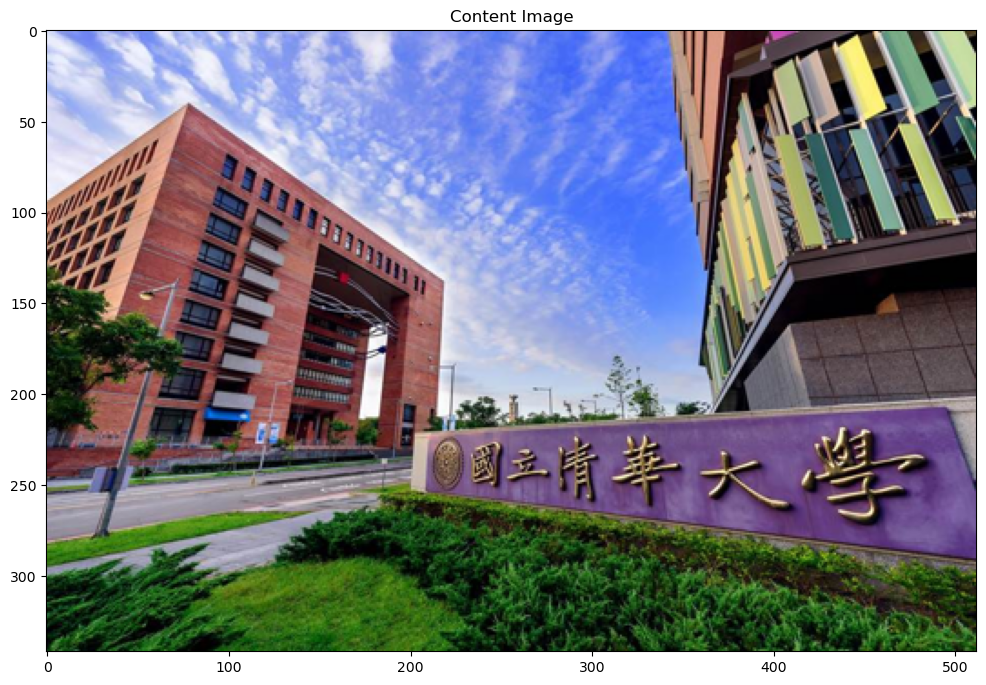

In [18]:
content_path = './dataset/content_nthu.jpg'
content_image = load_img(content_path)
print('Image shape:', content_image.shape)
imshow(content_image, 'Content Image')

<h2 id="Load-a-pretrained-network-(VGG19)">Load a pretrained network (VGG19)</h2>

<p>We are going to visualize one of most remarkable neural networks, VGG19, which is introduced from this <a href="https://arxiv.org/abs/1409.1556">paper</a>, pretrained on ImageNet. VGG19 is known for its simplicity, using only 3×3 convolutional layers stacked on top of each other in increasing depth. The "19" in its name stands for the number of layers in the network. ImageNet is a large dataset used in ImageNet Large Scale Visual Recognition Challenge(ILSVRC). The training dataset contains around 1.2 million images composed of 1000 different types of objects. The pretrained network learned how to create useful representations of the data to differentiate between different classes.</p>
<p>Pretrained network is useful and conveninent for several further usage, such as style transfer, transfer learning, fine-tuning, and so on. Generally, using pretrained network can save a lot of time and also easier to train a model on more complex dataset or small dataset.</p>
<img alt="No description has been provided for this image" src="./figs/vgg19.jpg"/>

<p>Load a VGG19 and test run it on our image to ensure it's used correctly. The output of VGG19 is the probabilities corresponding to 1000 categories.</p>

In [ ]:
# torchvision's VGG19 expects ImageNet-normalized (mean/std, RGB) inputs,
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def vgg19_preprocess(image):
    """image: float tensor in [0, 1], shape (B, 3, H, W)."""
    return (image - IMAGENET_MEAN.to(image.device)) / IMAGENET_STD.to(image.device)

x = vgg19_preprocess(content_image)
x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)

# load pretrained network (VGG19), *with* the classification head
vgg = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).to(device).eval()
with torch.no_grad():
    prediction_probabilities = torch.softmax(vgg(x.to(device)), dim=1)
prediction_probabilities.shape

torch.Size([1, 1000])

<p>Obtain the top 5 predicted categories of the input image.</p>

In [20]:
imagenet_categories = VGG19_Weights.IMAGENET1K_V1.meta['categories']
top5_prob, top5_idx = prediction_probabilities[0].topk(5)
[(imagenet_categories[i], p.item()) for p, i in zip(top5_prob, top5_idx)]

[('library', 0.711884617805481),
 ('bookshop', 0.1299254149198532),
 ('cinema', 0.04822154343128204),
 ('church', 0.021439319476485252),
 ('bell cote', 0.010125498287379742)]

<p>Let's try to first print out the detailed structure of VGG19. There's no `.summary()` built into PyTorch (the closest 3rd-party equivalent is `torchinfo.summary`), so `print(vgg)` -- listing the modules -- is the standard way to inspect an `nn.Module`'s structure.</p>

In [21]:
print(vgg)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padd

<h2 id="Visualize-filters">Visualize filters</h2>

<p>Now we can visualize the weights of the convolution filters to help us understand what neural network have learned. In neural network terminology, the learned filters are simply weights, yet because of the specialized two-dimensional structure of the filters, the weight values have a spatial relationship to each other and plotting each filter as a two-dimensional image is meaningful (or could be).</p>
<p>We can access the block of filters and the block of bias values through <code>layer.get_weight()</code>. In VGG19, all convolitional layers use 3x3 filters.</p>

In [22]:
# summarize filter shapes -- torchvision's VGG19 keeps all conv layers
# inside the `.features` Sequential, named by their index
for name, layer in vgg.features.named_children():
    if isinstance(layer, nn.Conv2d):
        print(f'features.{name}', tuple(layer.weight.shape))  # (out_ch, in_ch, kH, kW)

features.0 (64, 3, 3, 3)
features.2 (64, 64, 3, 3)
features.5 (128, 64, 3, 3)
features.7 (128, 128, 3, 3)
features.10 (256, 128, 3, 3)
features.12 (256, 256, 3, 3)
features.14 (256, 256, 3, 3)
features.16 (256, 256, 3, 3)
features.19 (512, 256, 3, 3)
features.21 (512, 512, 3, 3)
features.23 (512, 512, 3, 3)
features.25 (512, 512, 3, 3)
features.28 (512, 512, 3, 3)
features.30 (512, 512, 3, 3)
features.32 (512, 512, 3, 3)
features.34 (512, 512, 3, 3)


<p>Let's look at every single individual filter in the first convolutional layer. We will see all 64 in the block and plot each of the three channels. It is worth to meantion that in the first convolutional layer, it has total 192 feature maps(64 filters * 3 channels). We can normalize their values to the range 0-1 to make them easy to visualize.</p>
<p>The dark squares indicate small or inhibitory weights and the light squares represent large or excitatory weights. Using this intuition, we can see that the filters on the first row detect a gradient from light in the top left to dark in the bottom right.</p>

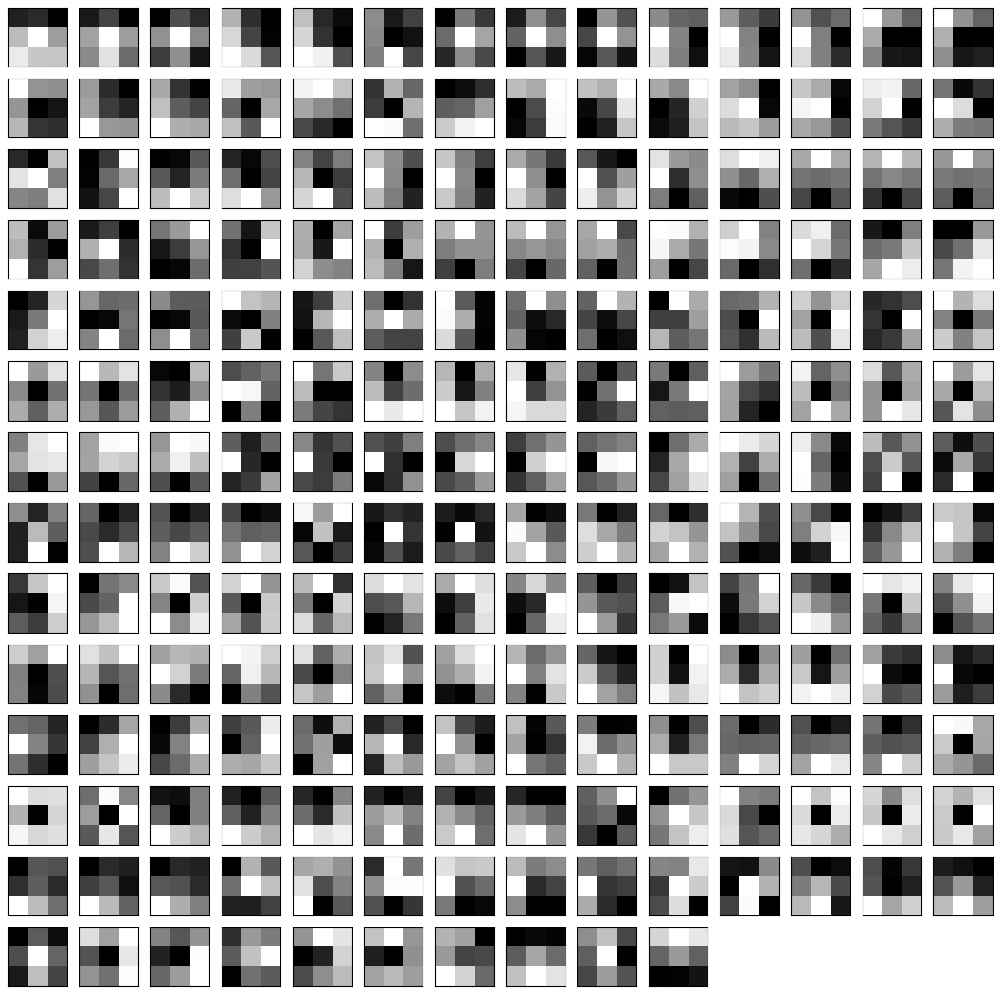

In [9]:
plt.figure(figsize=(16, 16))

# retrieve weights from the first conv layer (features[0])
filters = vgg.features[0].weight.detach().cpu()  # (out_ch=64, in_ch=3, 3, 3)

# normalize filter values to 0-1 so we can visualize them
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

# plot first few filters
n_filters, ix = 64, 1

for i in range(n_filters):
    # get the filter
    f = filters[i]  # (in_ch=3, 3, 3)
    # plot each channel separately
    for j in range(3):
        # specify subplot and turn off axis
        ax = pyplot.subplot(14, 14, ix)
        ax.set_xticks([])
        ax.set_yticks([])
        # plot filter channel in grayscale
        pyplot.imshow(f[j], cmap='gray')
        ix += 1

# show the figure
pyplot.show()

<h2 id="Visualize-feature-maps">Visualize feature maps</h2>

<p>The activation maps, called feature maps, capture the result of applying the filters to input, such as the input image or another feature map. The idea of visualizing a feature map for a specific input image would be to understand what features of the input are detected or preserved in the feature maps. The expectation would be that the feature maps close to the input detect small or fine-grained detail, whereas feature maps close to the output of the model capture more general features.</p>
<p>We can see that the result of applying the filters in the first convolutional layer is a lot of versions of the input image with different features highlighted. For example, some highlight lines, other focus on the background or the foreground.</p>

In PyTorch, grabbing "the output right after a chosen layer" is done with a **forward hook** registered on that submodule, instead of building a new `Model(inputs=..., outputs=layer.output)` sub-graph like Keras' functional API.

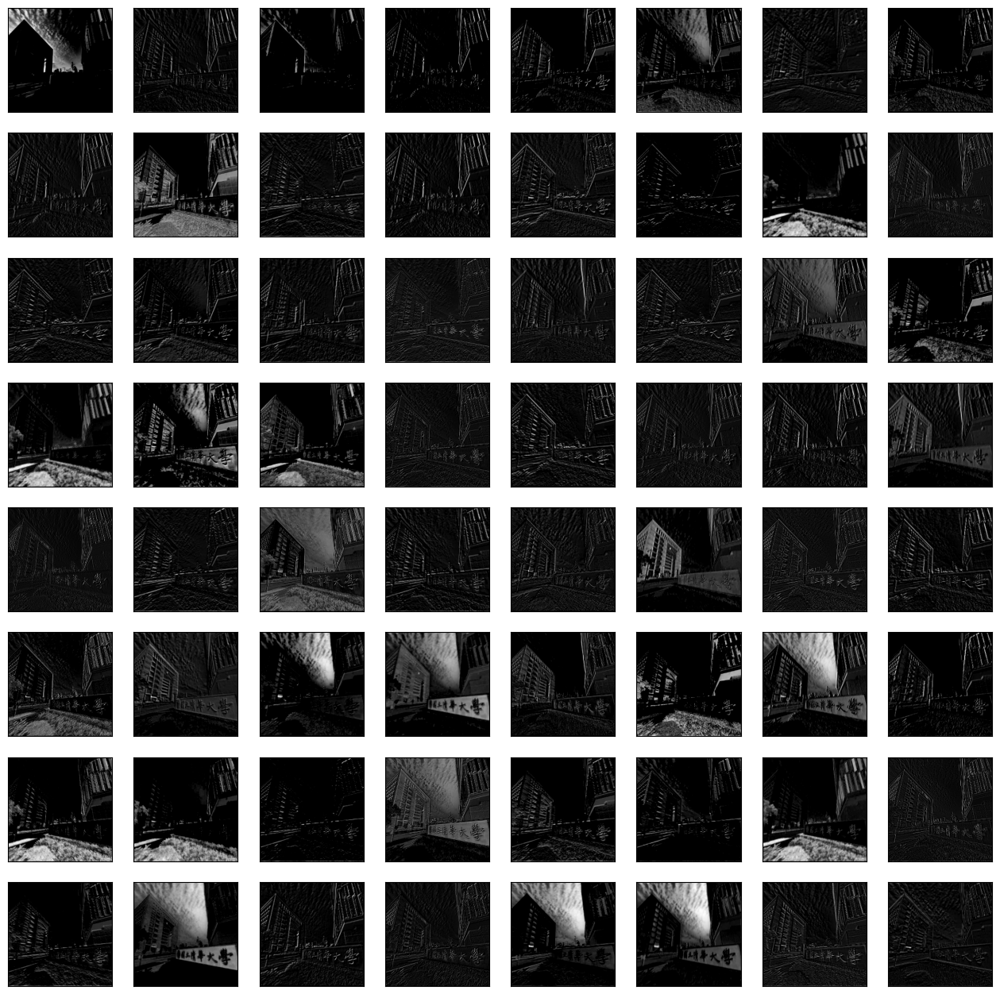

In [10]:
plt.figure(figsize=(16, 16))

# capture the output right after the first conv+relu (features[0], features[1])
activations = {}
def save_activation(name):
    def hook(module, inp, out):
        activations[name] = out.detach()
    return hook

handle = vgg.features[1].register_forward_hook(save_activation('block1'))

# preprocess input
content_image_pp = vgg19_preprocess(content_image)
content_image_pp = F.interpolate(content_image_pp, size=(224, 224), mode='bilinear', align_corners=False)

# get feature map for first hidden layer
with torch.no_grad():
    vgg(content_image_pp.to(device))
handle.remove()
feature_maps = activations['block1'][0].cpu()  # (64, 224, 224)

# plot all 64 maps in an 8x8 grid
square = 8
ix = 1
for _ in range(square):
    for _ in range(square):
        ax = pyplot.subplot(square, square, ix)
        ax.set_xticks([])
        ax.set_yticks([])
        pyplot.imshow(feature_maps[ix - 1], cmap='gray')
        ix += 1

pyplot.show()

<p>Let's visualize the feature maps output from each block of the model. You might notice that the number of feature maps (e.g. depth or number of channels) in deeper layers is much more than 64, such as 256 or 512. Nevertheless, we can cap the number of feature maps visualized at 64 for consistency.</p>
<p>We can see that the feature maps closer to the input of the model capture a lot of fine detail in the image and that as we progress deeper into the model, the feature maps show less and less detail.</p>
<p>This pattern was to be expected, as the model abstracts the features from the image into more general concepts that can be used to make a classification. Although it is not clear from the final image that the model saw NTHU campus, we generally lose the ability to interpret these deeper feature maps.</p>

features[3] (64, 224, 224)


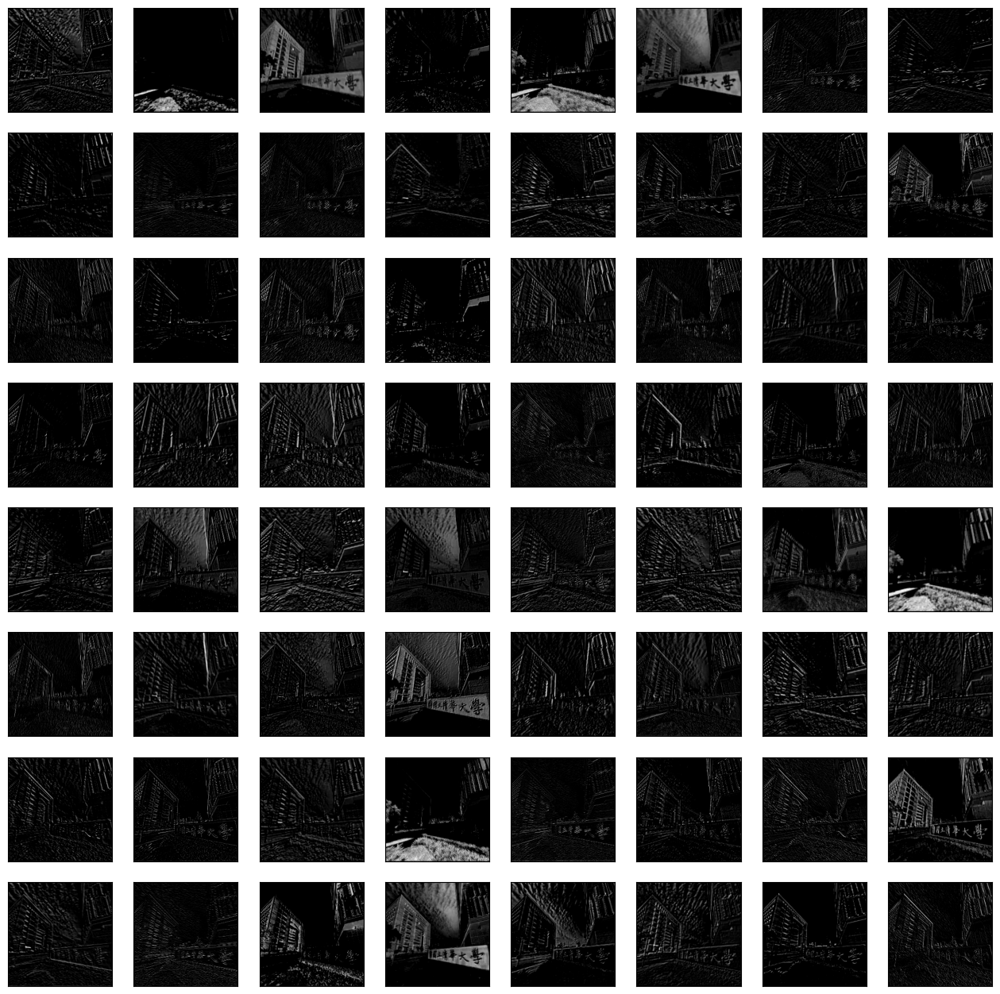

features[8] (128, 112, 112)


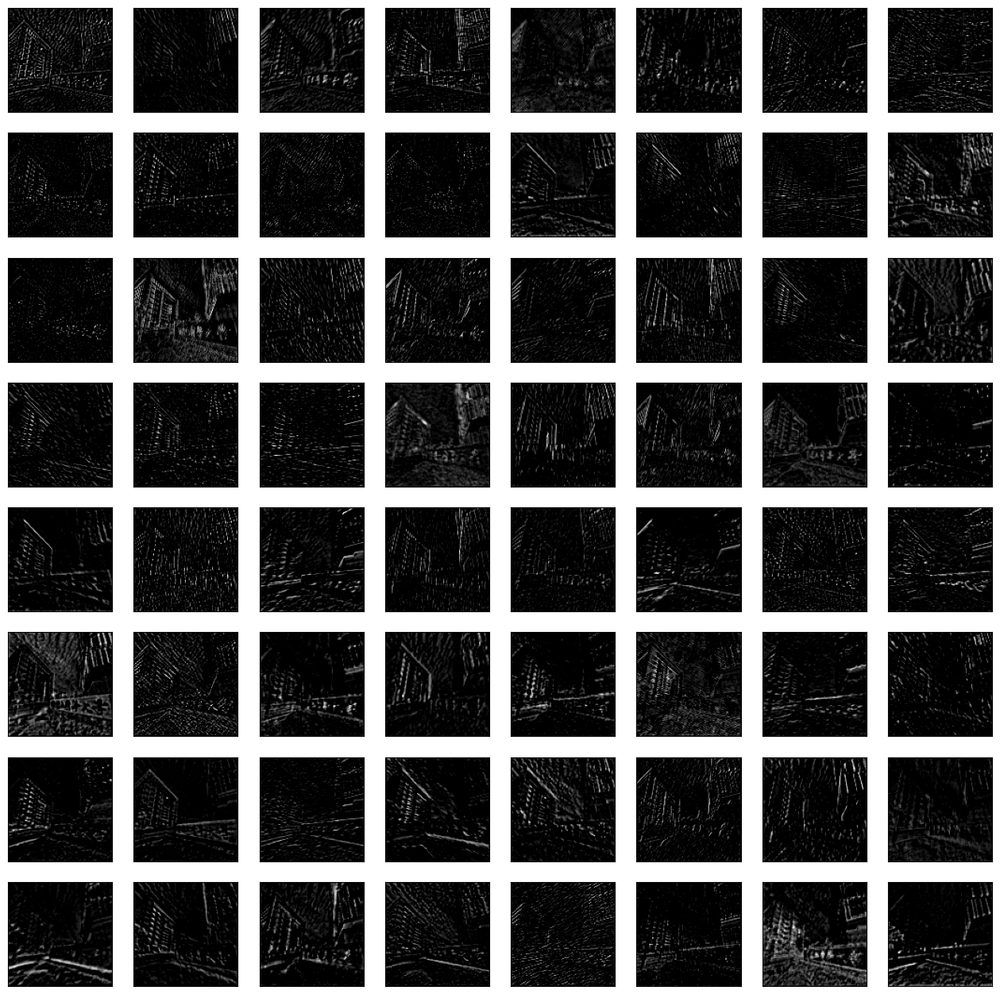

features[17] (256, 56, 56)


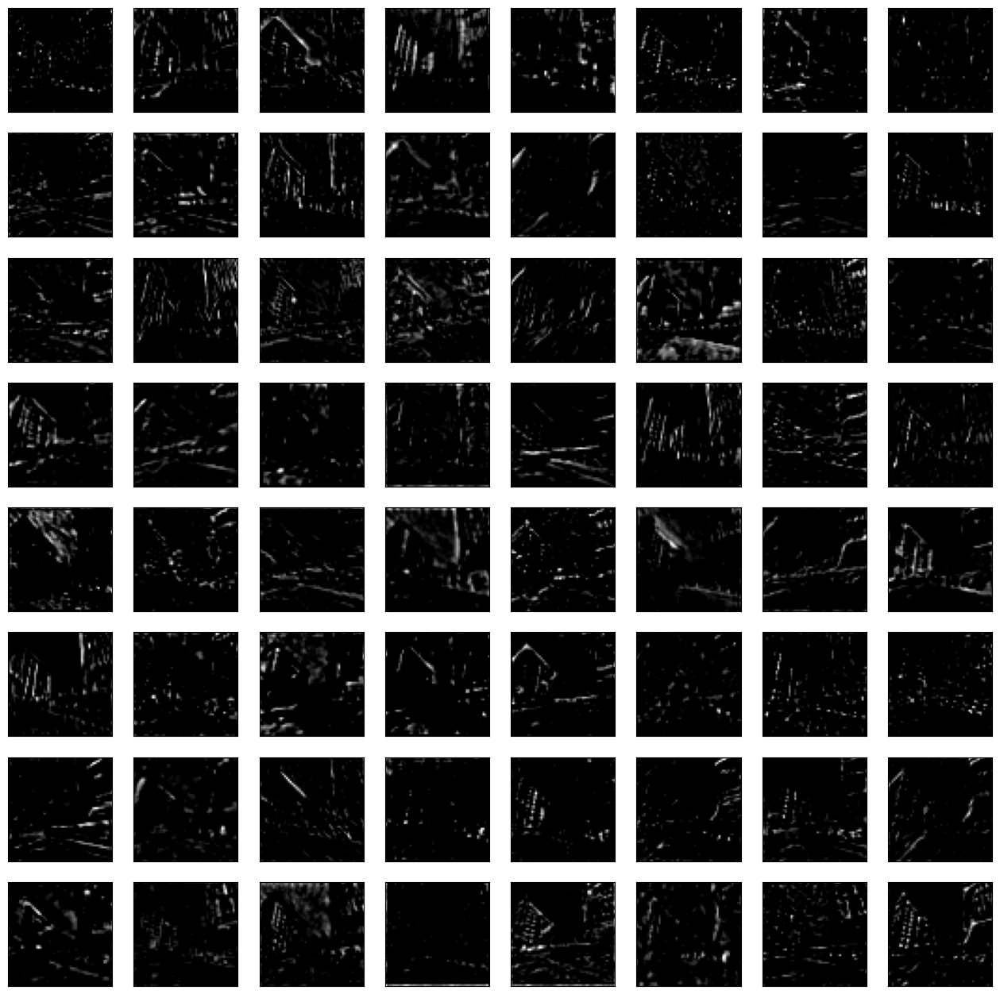

features[26] (512, 28, 28)


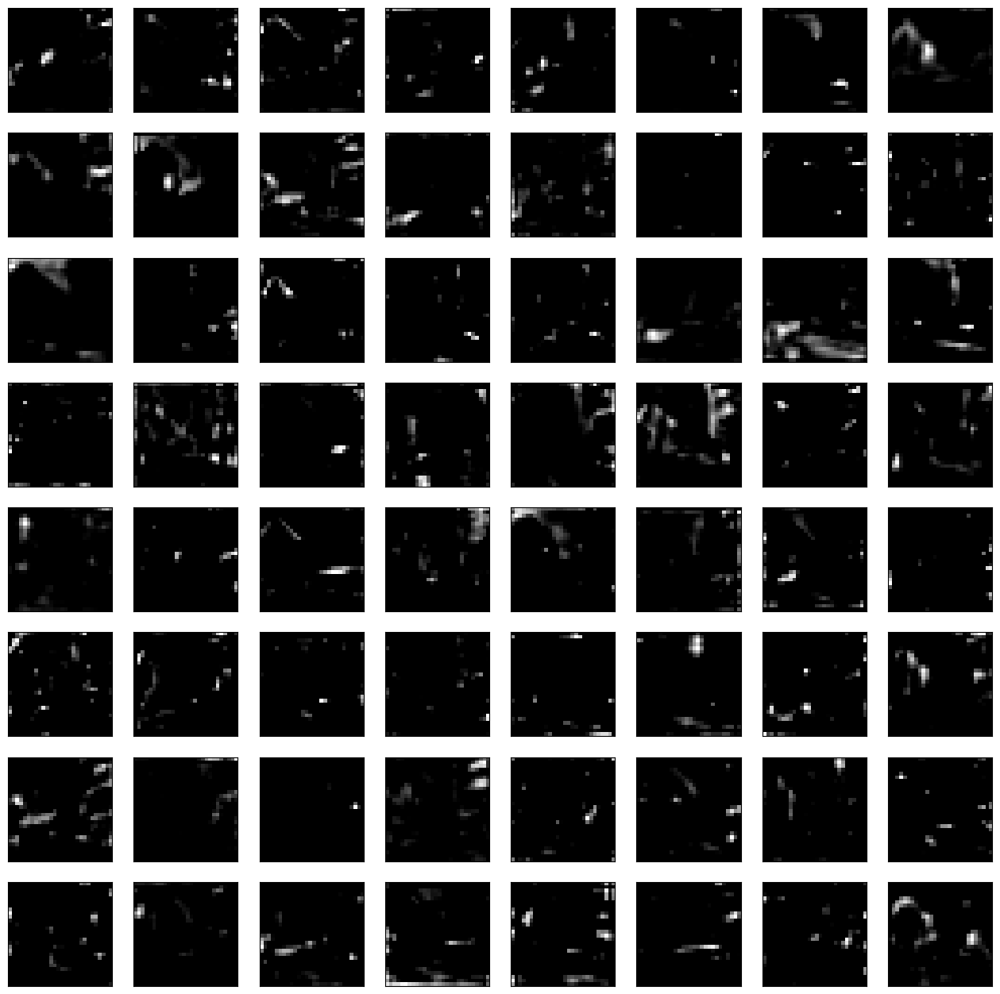

features[35] (512, 14, 14)


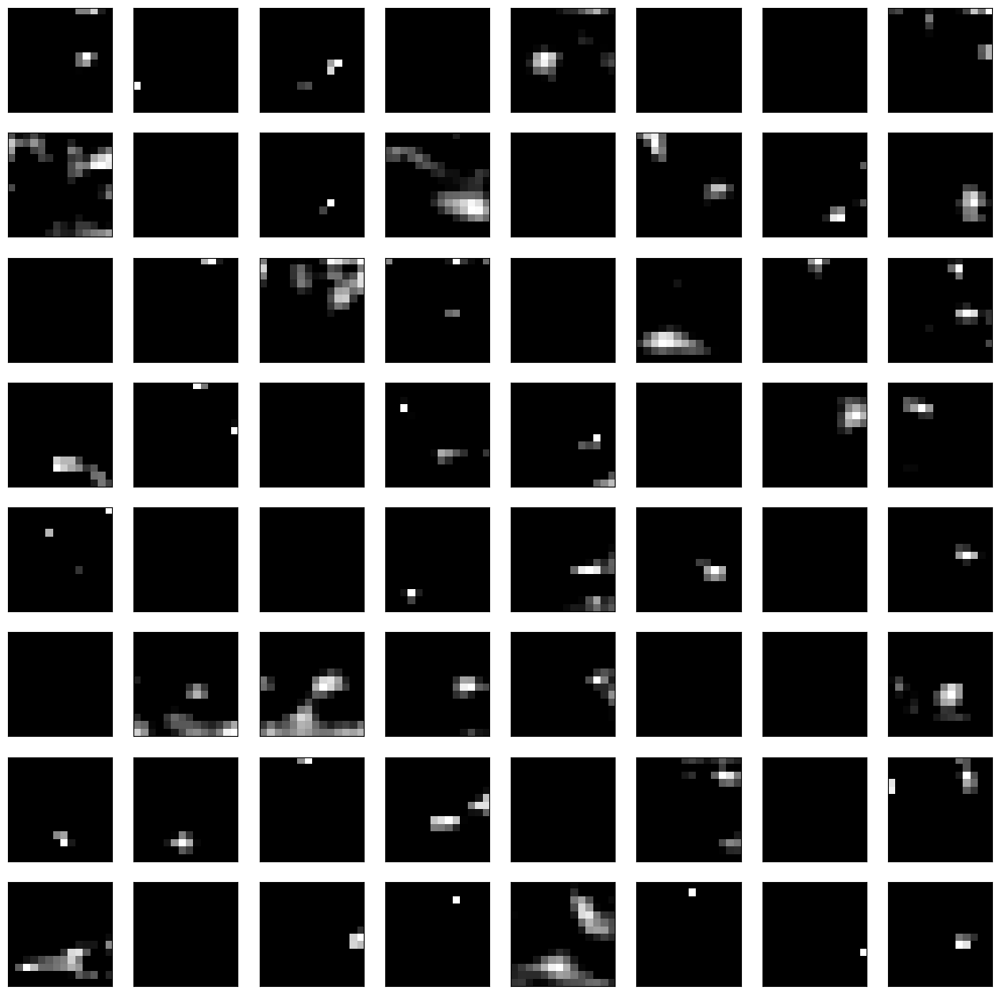

In [11]:
# get feature maps for the last conv+relu in each of the first 5 blocks
# (indices into vgg.features -- the PyTorch analogue of the Keras layer indices
# [2, 5, 10, 15, 20], i.e. block1_conv2/block2_conv2/block3_conv4/block4_conv4/
# block5_conv4 -- note Keras' Conv2D fuses the activation in, so "layer.output"
# there is already post-ReLU; here we grab the ReLU module right after each of
# those conv layers to match)
block_layer_indices = [3, 8, 17, 26, 35]
activations = {}
handles = [vgg.features[i].register_forward_hook(save_activation(i)) for i in block_layer_indices]

with torch.no_grad():
    vgg(content_image_pp.to(device))
for h in handles:
    h.remove()

# plot the output from each block
square = 8
for i in block_layer_indices:
    fmap = activations[i][0].cpu()
    print(f'features[{i}]', tuple(fmap.shape))
    plt.figure(figsize=(16, 16))
    ix = 1
    for _ in range(square):
        for _ in range(square):
            ax = pyplot.subplot(square, square, ix)
            ax.set_xticks([])
            ax.set_yticks([])
            pyplot.imshow(fmap[ix - 1], cmap='gray')
            ix += 1
    pyplot.show()

<h2 id="Visualize-gradients">Visualize gradients</h2>

<p>Visualizing convolutional output is a pretty useful technique for visualizing shallow convolution layers, but when we get into the deeper layers, it's hard to understand them just by just looking at the convolution output.</p>
<p>If we want to understand what the deeper layers are really doing, we can try to use backpropagation to show us the gradients of a particular neuron with respect to our input image. We will make a forward pass up to the layer that we are interested in, and then backpropagate to help us understand which pixels contributed the most to the activation of that layer.</p>
<p>We first create an operation which will find the maximum neurons among all activations in the required layer, and then calculate the gradient of that objective with respect to the input image.</p>

Extracting intermediate layers by name is the same idea as `vgg.get_layer(name).output` in Keras -- here we just index into the `features` `Sequential` and register a forward hook, wrapped in a small helper class so it can be reused (`VggIntermediateLayers` plays the role of the original `vgg_layers(layer_names)` function + Keras functional sub-model).

In [ ]:
class VggIntermediateLayers(nn.Module):
    """A VGG19 feature extractor that returns the outputs of several named
    intermediate layers, *in the order requested* (duplicates allowed)."""
    def __init__(self, layer_indices):
        super().__init__()
        backbone = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features
        backbone.requires_grad_(False)
        backbone.eval()
        self.backbone = backbone
        self.layer_indices = list(layer_indices)  # order matters; may repeat an index

    def forward(self, x):
        max_idx = max(self.layer_indices)
        captured = {}
        for i, layer in enumerate(self.backbone):
            x = layer(x)
            if i in self.layer_indices:
                captured[i] = x
            if i == max_idx:
                break
        return [captured[i] for i in self.layer_indices]

`block4_conv2` etc. named layers in Keras' VGG19 correspond to these indices into torchvision's `vgg19().features` -- both networks have the identical architecture (2/2/4/4/4 conv layers per block with ReLUs and max-pools between), just addressed differently:

In [24]:
# name -> index into torchvision's vgg19().features
VGG19_LAYER_INDEX = {
    'block1_conv1': 0, 'block1_conv2': 2,
    'block2_conv1': 5, 'block2_conv2': 7,
    'block3_conv1': 10, 'block3_conv2': 12, 'block3_conv3': 14, 'block3_conv4': 16,
    'block4_conv1': 19, 'block4_conv2': 21, 'block4_conv3': 23, 'block4_conv4': 25,
    'block5_conv1': 28, 'block5_conv2': 30, 'block5_conv3': 32, 'block5_conv4': 34,
}

class GradientModel(nn.Module):
    def __init__(self, layer_names):
        super().__init__()
        indices = [VGG19_LAYER_INDEX[n] for n in layer_names]
        self.vgg = VggIntermediateLayers(indices)

    def forward(self, inputs):
        "Expects float input in [0, 1]"
        preprocessed_input = vgg19_preprocess(inputs)
        return self.vgg(preprocessed_input)[0]

<p>Compute the gradient of maximum neurons among all activations in the required layer with respect to the input image.</p>

In [14]:
def visualize_gradient(image):
    image = image.clone().requires_grad_(True)
    feature = extractor(image)
    # grad = d(max over channels of feature)/d_image
    grad, = torch.autograd.grad(feature.amax(dim=1).sum(), image)
    return grad

In [15]:
content_image = load_img(content_path)

# activation layer
layer_names = ['block4_conv2']
image = content_image.clone().to(device)

extractor = GradientModel(layer_names).to(device)
grad = visualize_gradient(image)

# look at the range of gradients
print('shape: ', tuple(grad.shape))
print('min: ', grad.min().item())
print('max: ', grad.max().item())
print('mean: ', grad.mean().item())

shape:  (1, 3, 342, 512)
min:  -239.50308227539062
max:  322.0506591796875
mean:  -0.07001073658466339


<p>It is hard to understand the gradient in that range of values. We can normalize the gradient in a way that lets us see it more in terms of the normal range of color values. After normalizing the gradient values, let's visualize the original image and the output of the backpropagated gradient.</p>

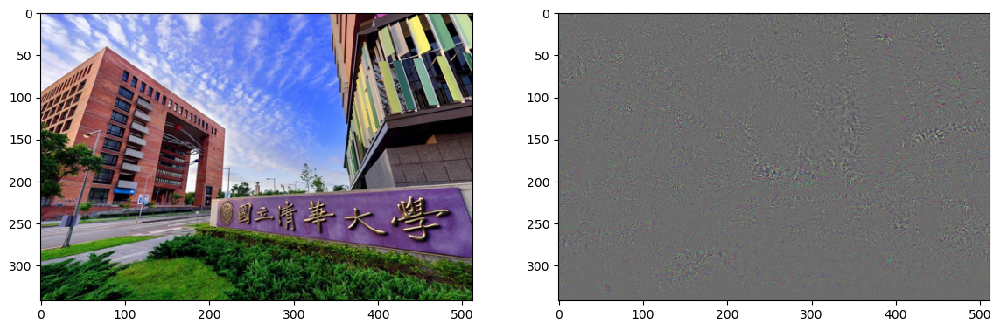

In [16]:
# normalize filter values to 0-1 so we can visualize them
g_min, g_max = grad.min(), grad.max()
filters = (grad - g_min) / (g_max - g_min)

plt.figure(figsize=(14, 10))
plt.subplot(1, 2, 1)
imshow(image[0])

plt.subplot(1, 2, 2)
imshow(filters[0])

<p>We can also visualize the gradient of any single feature map.</p>

In [17]:
def visualize_gradient_single_layer(image, layer_i):
    image = image.clone().requires_grad_(True)
    feature = extractor(image)
    grad, = torch.autograd.grad(feature[:, layer_i].mean(), image)
    return grad

<Figure size 1400x1000 with 0 Axes>

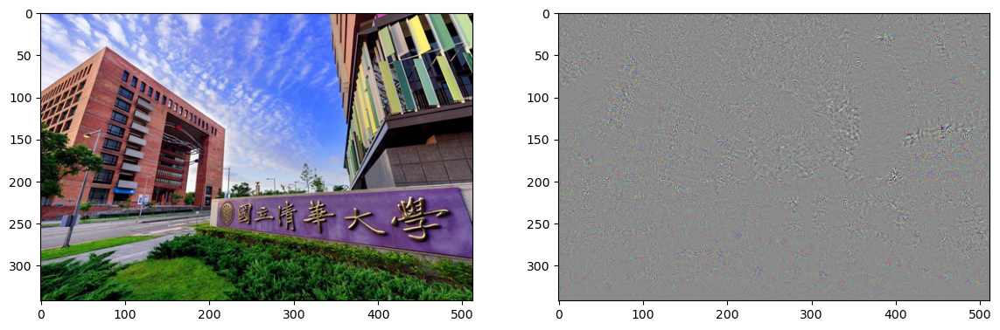

In [18]:
plt.figure(figsize=(14, 10))

grad = visualize_gradient_single_layer(image, 77)

# normalize filter values to 0-1 so we can visualize them
g_min, g_max = grad.min(), grad.max()
filters = (grad - g_min) / (g_max - g_min)

plt.figure(figsize=(14, 10))
plt.subplot(1, 2, 1)
imshow(image[0])

plt.subplot(1, 2, 2)
imshow(filters[0])

<h2 id="Guided-Backpropagation">Guided-Backpropagation</h2><p>As we can see above, the results are still hard to explain and not very satisfying. Every pixel influences the neuron via multiple hidden neurons.</p>
<p>Ideally, neurons act like detectors of particular image features. We are only interested in what image features the
neuron detects, not in what kind of stuff it doesn’t detect. Therefore, when propagating the gradient, we set all the
negative gradients to 0.</p>
<img alt="No description has been provided for this image" src="./figs/visualization.png" width="900"/>
<p>We call this method <strong>guided backpropagation</strong>, because it adds an additional guidance signal from the higher layers to usual backpropagation. This prevents backward flow of negative gradients, corresponding to the neurons which decrease the activation of the higher layer unit we aim to visualize. For more details, please refer to <a href="https://arxiv.org/pdf/1412.6806.pdf">Striving for Simplicity: The All Convolutional Net</a>, a nice work from J. T. Springenberg and A. Dosovitskiy et al.</p>

In [ ]:
import urllib.request
if not os.path.exists("guided_backprop.py"):
    urllib.request.urlretrieve("https://nthu-datalab.github.io/ml/labs/11-2_Visualization_Style-Transfer/guided_backprop.py", "guided_backprop.py")

In [19]:
from guided_backprop import GuidedBackprop

In [20]:
x = vgg19_preprocess(content_image)
x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False).to(device)

# backprop_vgg = GuidedBackprop(vgg, layer_name='classifier.6')  # original (last FC layer)
backprop_vgg = GuidedBackprop(vgg.features)  # auto-detects the last 4D-output conv layer
grad = backprop_vgg.guided_backprop(x)[0].permute(1, 2, 0).cpu().numpy()

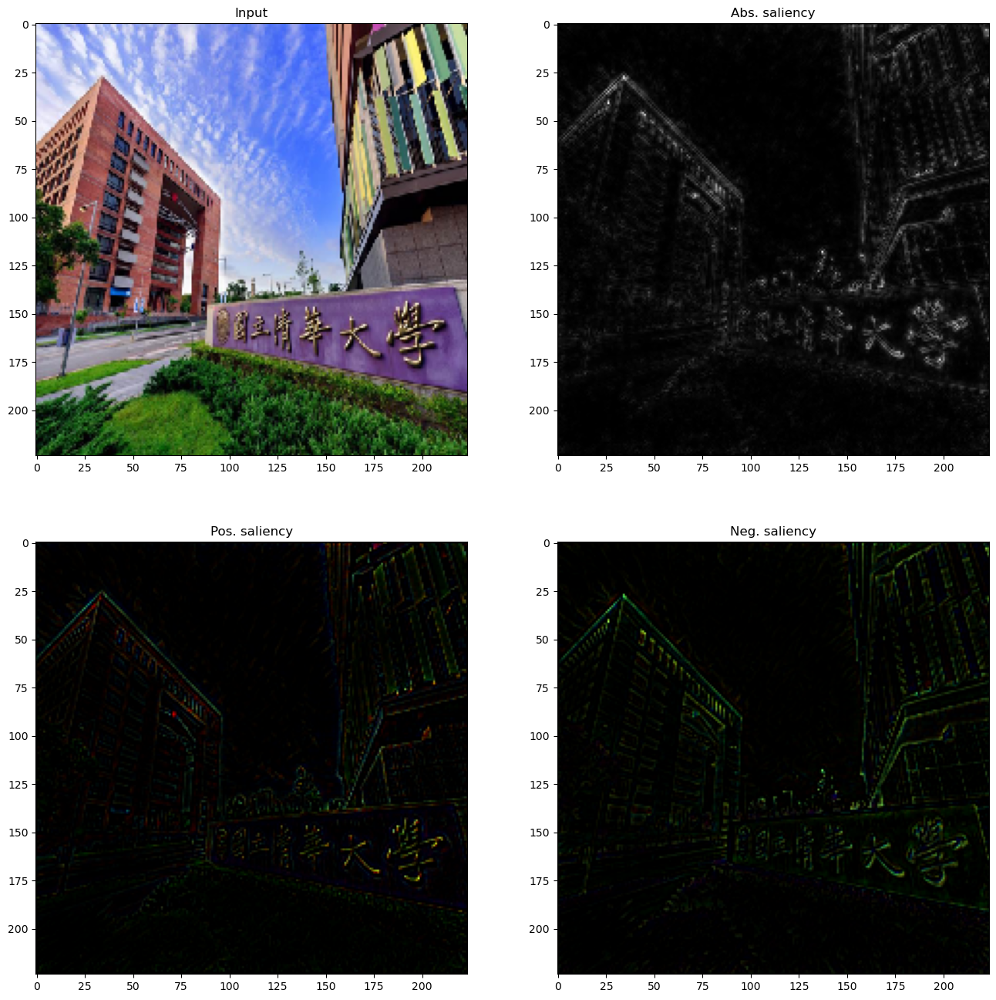

In [21]:
# plot the original image and the three saliency map variants
plt.figure(figsize=(16, 16), facecolor='w')
plt.subplot(2, 2, 1)
plt.title('Input')
plt.imshow(F.interpolate(content_image, size=(224, 224))[0].permute(1, 2, 0))
plt.subplot(2, 2, 2)
plt.title('Abs. saliency')
plt.imshow(np.abs(grad).max(axis=-1), cmap='gray')
plt.subplot(2, 2, 3)
plt.title('Pos. saliency')
plt.imshow((np.maximum(0, grad) / grad.max()))
plt.subplot(2, 2, 4)
plt.title('Neg. saliency')
plt.imshow((np.maximum(0, -grad) / -grad.min()))
plt.show()

<h1><center class="subtitle">A Neural Algorithm of Artistic Style</center></h1>

<p>Visualizing neural network gives us a better understanding of what's going in the mysterious huge network. Besides from this application, Leon Gatys and his co-authors has a very interesting work called <a href="https://arxiv.org/abs/1508.06576">"A Neural Algorithm of Artistic Style"</a> that uses neural representations to separate and recombine content and style of arbitrary images, providing a neural algorithm for the creation of artistic images.</p>

<img alt="No description has been provided for this image" src="./dataset/nthu_candy.jpg" width="800"/>
<img alt="No description has been provided for this image" src="./dataset/style_transfer_nthu_candy.png"/>

<h2 id="Define-content-and-style-representations">Define content and style representations</h2>

<p>Use the intermediate layers of the model to get the content and style representations of the image. Starting from the network's input layer, the first few layers' activations represent low-level features like edges and textures. As you step through the network, the final few layers represent higher-level features—object parts like wheels or eyes. In this case, you are using the VGG19 network architecture, a pretrained image classification network. These intermediate layers are necessary to define the representation of content and style from the images. For an input image, try to match the corresponding style and content target representations at these intermediate layers.</p>

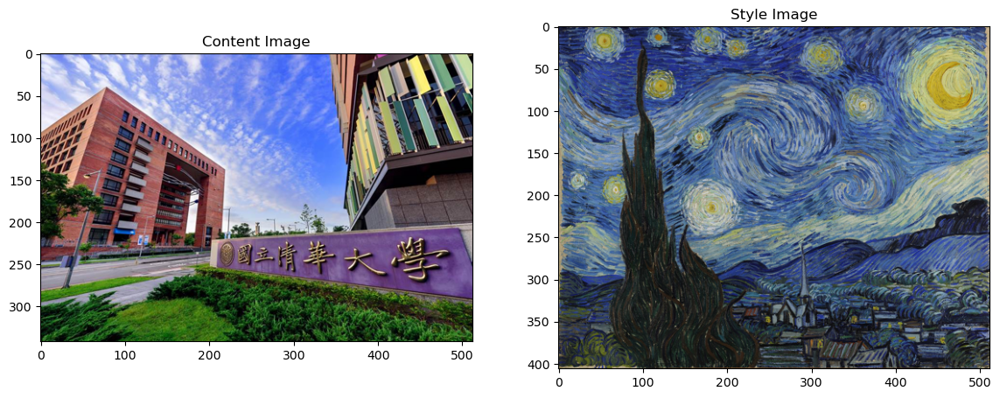

In [137]:
content_path = './dataset/content_nthu.jpg'
style_path = './dataset/style_starry_night.jpg'

content_image = load_img(content_path)
style_image = load_img(style_path)

plt.figure(figsize=(14, 10))
plt.subplot(1, 2, 1)
imshow(content_image, 'Content Image')

plt.subplot(1, 2, 2)
imshow(style_image, 'Style Image')

<p>Now load a VGG19 without the classification head, and list the layer names.</p>

In [138]:
vgg = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).to(device).eval()

print()
for name, layer in vgg.features.named_children():
    print(f'features.{name}', layer.__class__.__name__)


features.0 Conv2d
features.1 ReLU
features.2 Conv2d
features.3 ReLU
features.4 MaxPool2d
features.5 Conv2d
features.6 ReLU
features.7 Conv2d
features.8 ReLU
features.9 MaxPool2d
features.10 Conv2d
features.11 ReLU
features.12 Conv2d
features.13 ReLU
features.14 Conv2d
features.15 ReLU
features.16 Conv2d
features.17 ReLU
features.18 MaxPool2d
features.19 Conv2d
features.20 ReLU
features.21 Conv2d
features.22 ReLU
features.23 Conv2d
features.24 ReLU
features.25 Conv2d
features.26 ReLU
features.27 MaxPool2d
features.28 Conv2d
features.29 ReLU
features.30 Conv2d
features.31 ReLU
features.32 Conv2d
features.33 ReLU
features.34 Conv2d
features.35 ReLU
features.36 MaxPool2d


<ul>
<li><p>Content features of the content image is calculated by feeding the content image into the neural network, and extract the activations of those <code>content_layers</code>.</p>
</li>
<li><p>For style features, we extract the correlation of the features of the style-image layer-wise (gram matrix). By adding up the feature correlations of multiple layers, which corresponding to <code>style_layers</code>, we obtain a multi-scale representation of the input image, which captures its texture information instead of the object arrangement in the input image.</p>
</li>
</ul>

In [139]:
# Content layer where we will pull our feature maps
content_layers = ['block5_conv2']

# Style layers of interest
style_layers = ['block1_conv1',
                'block2_conv1',
                'block3_conv1',
                'block4_conv1',
                'block5_conv1']

num_content_layers = len(content_layers)
num_style_layers = len(style_layers)

<p>At a high level, in order for a network to perform image classification (which this network has been trained to do), it must understand the image. This requires taking the raw image as input pixels and building an internal representation that converts the raw image pixels into a complex understanding of the features present within the image.</p>
<p>This is also a reason why convolutional neural networks are able to generalize well: they’re able to capture the invariances and defining features within classes (e.g. cats vs. dogs) that are agnostic to background noise and other nuisances. Thus, between the raw image fed into the model and the output, in this case, the predicted label, the model serves as a complex feature extractor. By accessing intermediate layers of the model, you're able to describe the content and style of input images.</p>

<h2 id="Build-the-model">Build the model</h2>

In [140]:
def vgg_layers(layer_names):
    """Creates a VGG19 feature extractor that returns a list of
    intermediate output values, in the order requested."""
    return VggIntermediateLayers([VGG19_LAYER_INDEX[n] for n in layer_names])

In [141]:
style_extractor = vgg_layers(style_layers).to(device)
with torch.no_grad():
    style_outputs = style_extractor(vgg19_preprocess(style_image.to(device)))

# Look at the statistics of each layer's output
for name, output in zip(style_layers, style_outputs):
    print(name)
    print('  shape: ', tuple(output.shape))
    print('  min: ', output.min().item())
    print('  max: ', output.max().item())
    print('  mean: ', output.mean().item())
    print()

block1_conv1
  shape:  (1, 64, 406, 512)
  min:  0.0
  max:  10.763559341430664
  mean:  0.3961537480354309

block2_conv1
  shape:  (1, 128, 203, 256)
  min:  0.0
  max:  30.1450138092041
  mean:  0.9038920402526855

block3_conv1
  shape:  (1, 256, 101, 128)
  min:  0.0
  max:  61.72346115112305
  mean:  1.4844896793365479

block4_conv1
  shape:  (1, 512, 50, 64)
  min:  0.0
  max:  105.18870544433594
  mean:  1.2090039253234863

block5_conv1
  shape:  (1, 512, 25, 32)
  min:  -37.9304084777832
  max:  38.0362434387207
  mean:  -3.1062910556793213



<h2 id="Calculate-style">Calculate style</h2>

<p>The style of an image can be described by the means and correlations across the different feature maps. Calculate a Gram matrix that includes this information by taking the outer product of the feature vector with itself at each location, and averaging that outer product over all locations. This Gram matrix can be calcualted for a particular layer as:</p>

<center class="formula">$\cfrac{G^{l}_{cd} = \sum_{ij}F^{l}_{ijc}(x)F^{l}_{ijd}(x)}{IJ}$</center>

In [142]:
def gram_matrix(input_tensor):
    # input_tensor: (B, C, H, W) -- channels-first, vs. TF's channels-last
    # (B, H, W, C), so the einsum indices are permuted accordingly
    result = torch.einsum('bchw,bdhw->bcd', input_tensor, input_tensor)
    num_locations = input_tensor.shape[2] * input_tensor.shape[3]
    return result / num_locations

<h2 id="Extract-style-and-content">Extract style and content</h2>

In [143]:
class StyleContentModel(nn.Module):
    def __init__(self, style_layers, content_layers):
        super().__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = len(style_layers)

    def forward(self, inputs):
        "Expects float input in [0, 1]"
        preprocessed_input = vgg19_preprocess(inputs)
        outputs = self.vgg(preprocessed_input)
        style_outputs, content_outputs = (outputs[:self.num_style_layers],
                                           outputs[self.num_style_layers:])

        style_outputs = [gram_matrix(style_output) for style_output in style_outputs]

        content_dict = {content_name: value
                        for content_name, value
                        in zip(self.content_layers, content_outputs)}

        style_dict = {style_name: value
                      for style_name, value
                      in zip(self.style_layers, style_outputs)}

        return {'content': content_dict, 'style': style_dict}

In [144]:
extractor = StyleContentModel(style_layers, content_layers).to(device)

with torch.no_grad():
    results = extractor(content_image.to(device))

style_results = results['style']

print('Styles:')
for name, output in sorted(results['style'].items()):
    print('  ', name)
    print('    shape: ', tuple(output.shape))
    print('    min: ', output.min().item())
    print('    max: ', output.max().item())
    print('    mean: ', output.mean().item())
    print()

print('Contents:')
for name, output in sorted(results['content'].items()):
    print('  ', name)
    print('    shape: ', tuple(output.shape))
    print('    min: ', output.min().item())
    print('    max: ', output.max().item())
    print('    mean: ', output.mean().item())

Styles:
   block1_conv1
    shape:  (1, 64, 64)
    min:  0.0
    max:  2.633363723754883
    mean:  0.211969256401062

   block2_conv1
    shape:  (1, 128, 128)
    min:  3.384944284334779e-05
    max:  17.249900817871094
    mean:  1.0752267837524414

   block3_conv1
    shape:  (1, 256, 256)
    min:  0.0006775938090868294
    max:  60.860748291015625
    mean:  3.6095235347747803

   block4_conv1
    shape:  (1, 512, 512)
    min:  0.0
    max:  257.2108459472656
    mean:  3.4944446086883545

   block5_conv1
    shape:  (1, 512, 512)
    min:  0.0
    max:  29.909883499145508
    mean:  0.649518609046936

Contents:
   block5_conv2
    shape:  (1, 512, 21, 32)
    min:  -46.80270004272461
    max:  45.358642578125
    mean:  -4.616512775421143


<h2 id="Define-loss">Define loss</h2>

<p>Our goal is to create an output image which is synthesized by finding an image that simultaneously matches the content features of the photograph and the style features of the respective piece of art. How can we do that? We can define the loss function as the composition of:</p>
<ol>
<li>The dissimilarity of the content features between the output image and the content image</li>
<li>The dissimilarity of the style features between the output image and the style image to the loss function</li>
</ol>
<p>The following figure gives a very good visualization of the process:</p>

<img alt="No description has been provided for this image" src="./figs/fig-style-transfer-algorithm.png" width="800"/>

<ul>
<li>$G^{l}_{ij}$ is the inner product between the vectorised feature maps of the initial image $i$ and $j$ in layer $l$</li>
<li>$w_{l}$ is the weight of each style layers</li>
<li>$A^{l}$ is that of the style image</li>
<li>$F^{l}$ is layer-wise content features of the initial image</li>
<li>$P^{l}$ is that of the content image</li>
</ul>

In [145]:
def style_content_loss(outputs):
    style_outputs = outputs['style']
    content_outputs = outputs['content']
    style_loss = sum(torch.mean((style_outputs[name] - style_targets[name]) ** 2)
                      for name in style_outputs.keys())
    style_loss *= style_weight / num_style_layers

    content_loss = sum(torch.mean((content_outputs[name] - content_targets[name]) ** 2)
                        for name in content_outputs.keys())
    content_loss *= content_weight / num_content_layers
    return style_loss + content_loss

<h2 id="Run-gradient-descent">Run gradient descent</h2>

In [146]:
def clip_0_1(image):
    return image.clamp(0.0, 1.0)

Since we're optimizing the **image itself** (not a model's weights), the PyTorch training loop hands the image tensor straight to the optimizer as its one parameter -- there's no `tf.GradientTape` context manager needed, autograd just tracks operations on any tensor with `requires_grad=True`.

In [147]:
def train_step(image, optimizer):
    optimizer.zero_grad()
    outputs = extractor(image)
    loss = style_content_loss(outputs)
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        image.copy_(clip_0_1(image))

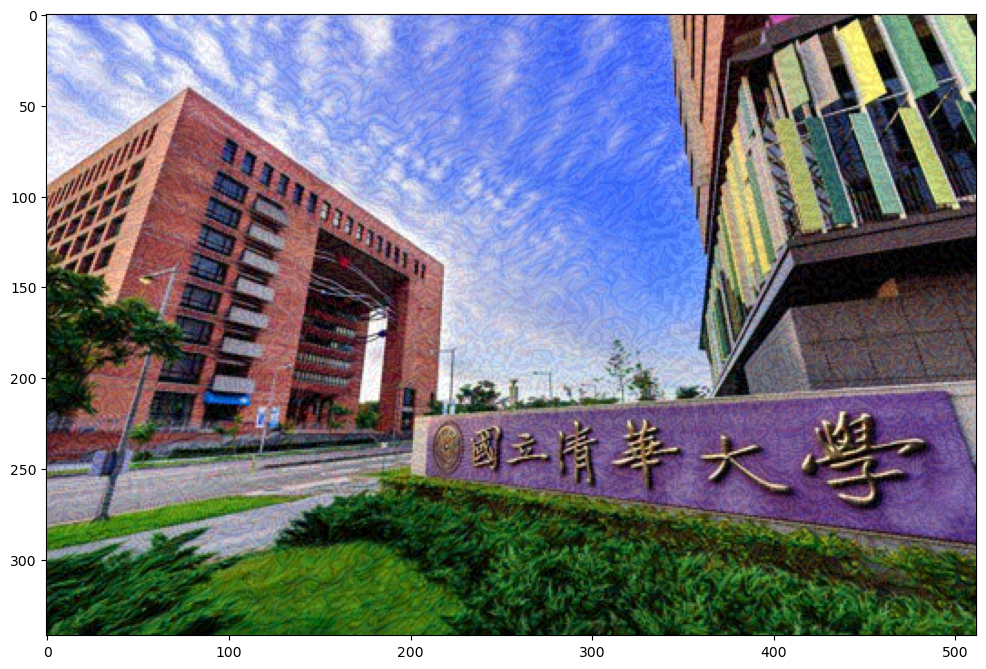

In [230]:
with torch.no_grad():
    style_targets = extractor(style_image.to(device))['style']
    content_targets = extractor(content_image.to(device))['content']

image = content_image.clone().to(device).requires_grad_(True)
opt = torch.optim.Adam([image], lr=0.02, betas=(0.99, 0.999), eps=1e-1)
style_weight = 1e3   # Change it as you want
content_weight = 1e2  # Change it as you want

train_step(image, opt)
train_step(image, opt)
train_step(image, opt)
plt.imshow(image[0].permute(1, 2, 0).detach().cpu())

<p>Let's train with more iteration to see the results!</p>

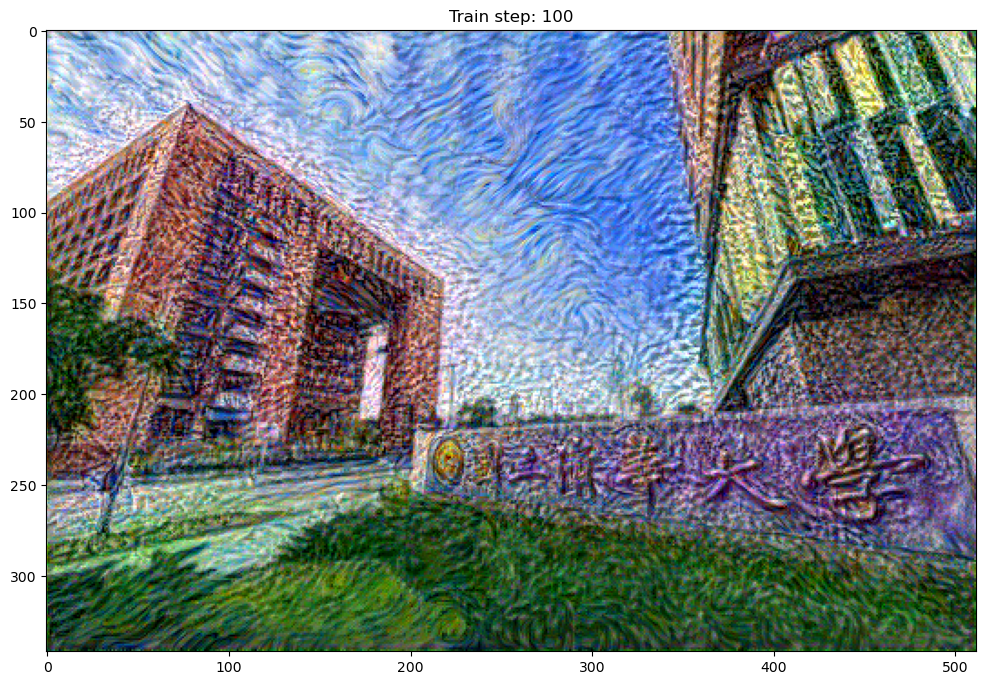

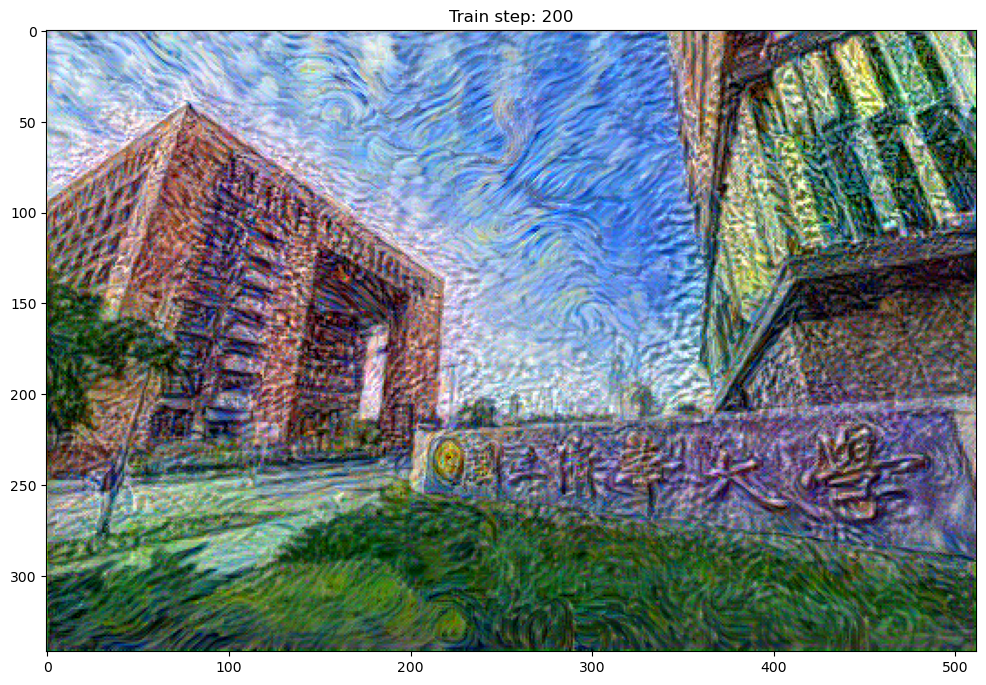

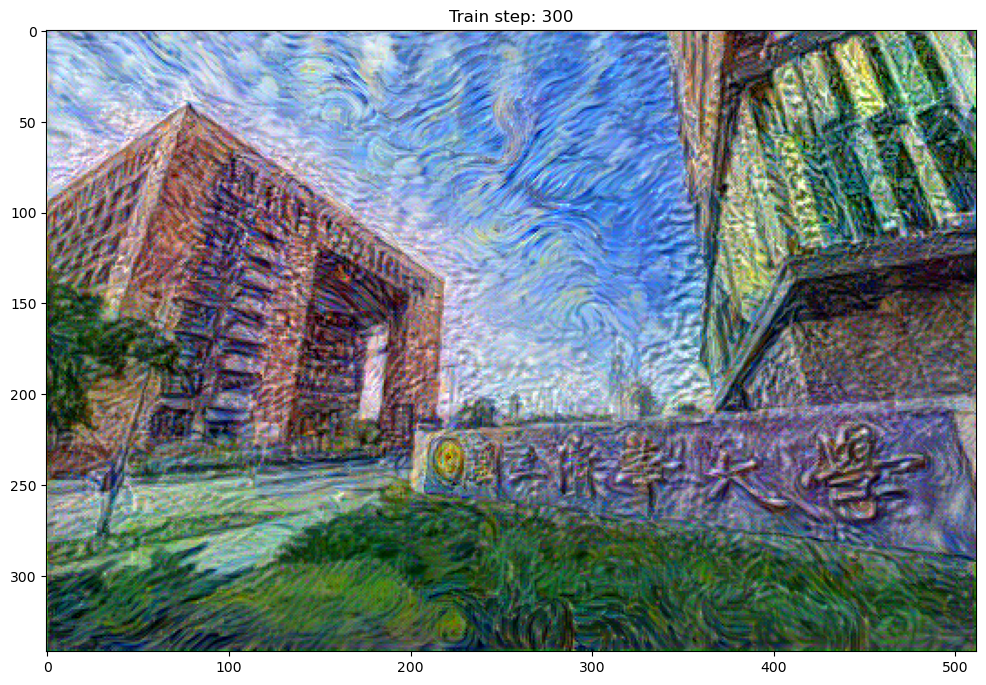

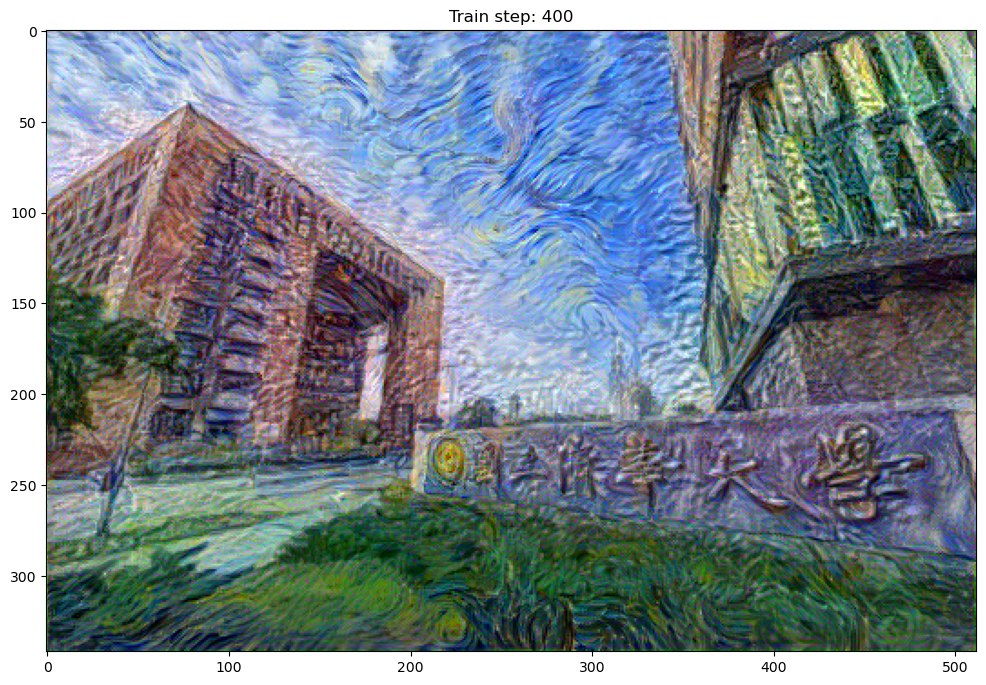

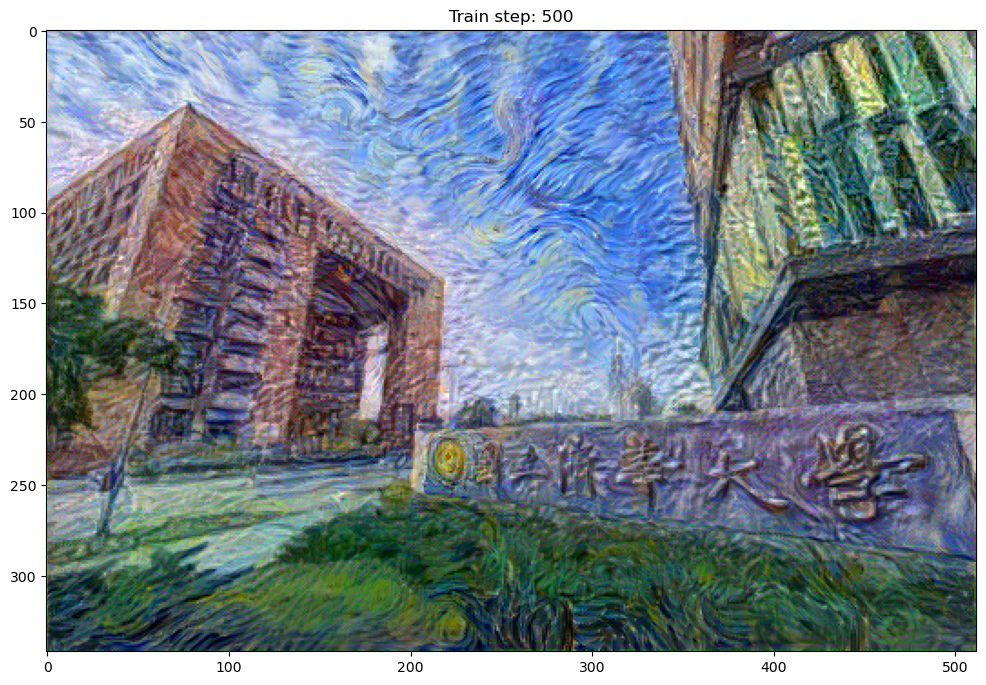

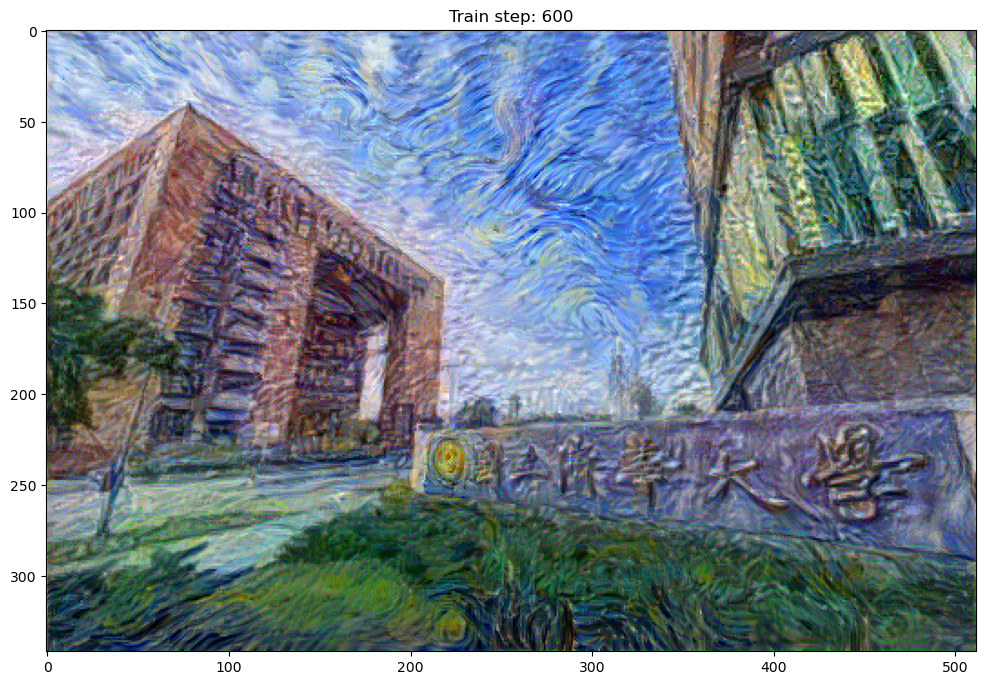

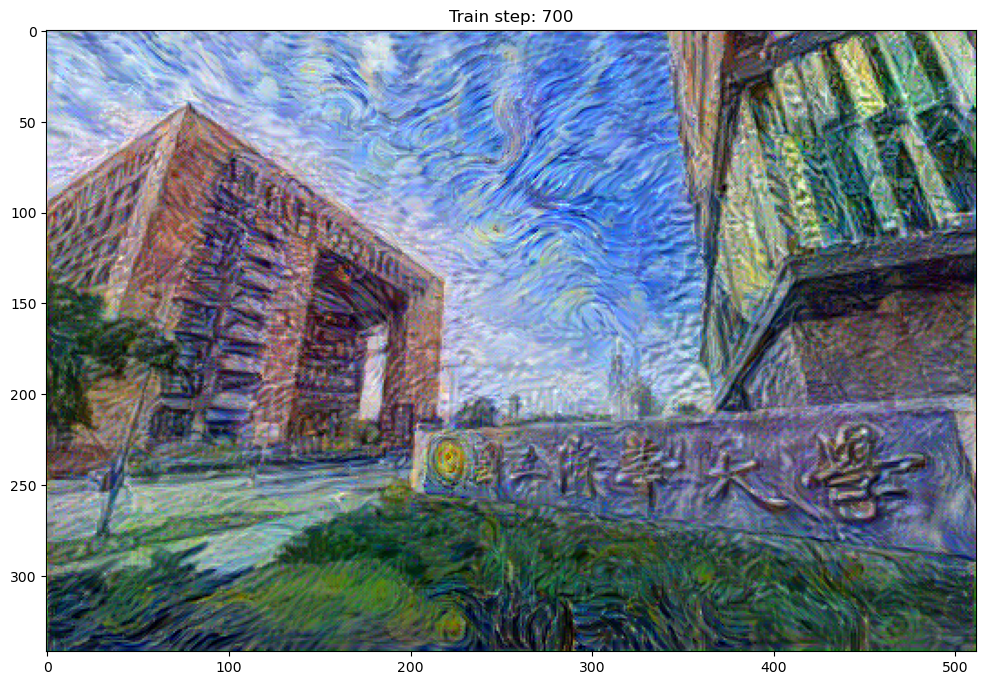

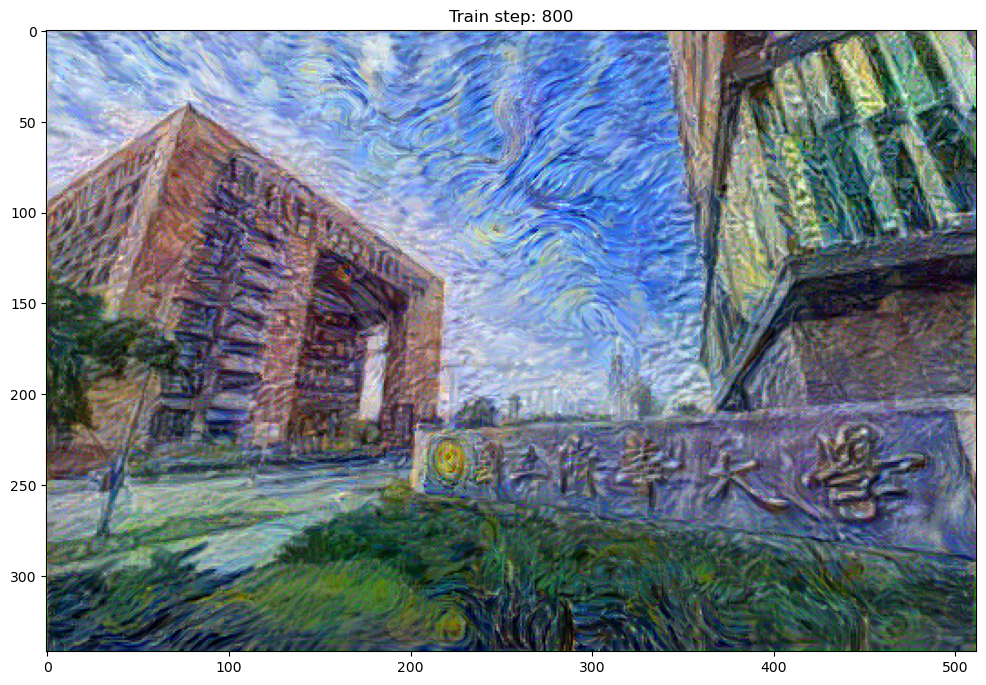

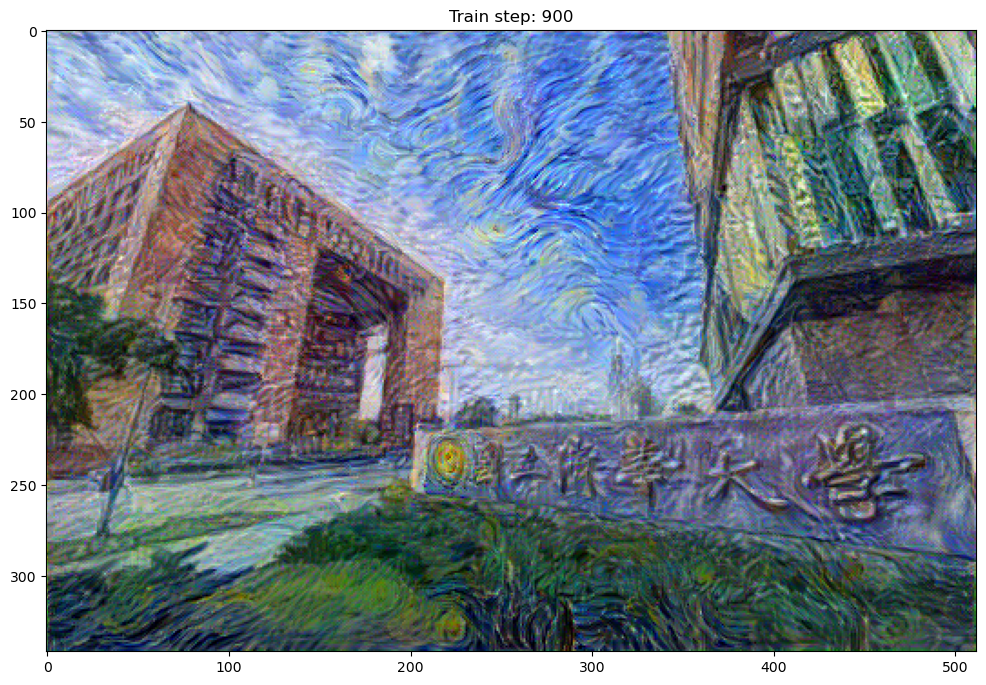

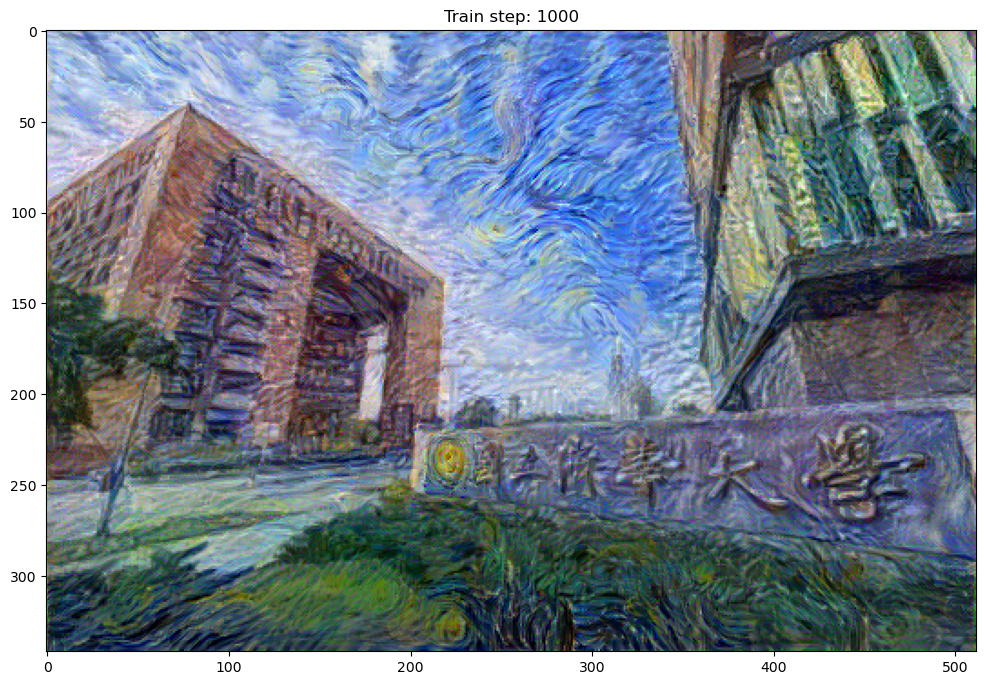

Total time: 26.7


In [231]:
import time
start = time.time()

epochs = 10
steps_per_epoch = 100

step = 0
for n in range(epochs):
    for m in range(steps_per_epoch):
        step += 1
        train_step(image, opt)
    imshow(image)
    plt.title('Train step: {}'.format(step))
    plt.show()

end = time.time()
print('Total time: {:.1f}'.format(end - start))

<h2 id="Total-variation-loss">Total variation loss</h2>

<p>One downside to this basic implementation is that it produces a lot of high frequency artifacts. Decrease these using an explicit regularization term on the high frequency components of the image. In style transfer, this is often called the total variation loss:</p>
<center class="formula">$V(y)=\sum_i \sum_j\sqrt{(y_{i+1,j}-y_{i,j})^2 + (y_{i,j+1}-y_{i,j})^2}$</center>
<p>In practice, to speed up the computation, we implement the following version instead:</p>
<center class="formula">$V(y)=\sum_i \sum_j|y_{i+1,j}-y_{i,j}| + |y_{i,j+1}-y_{i,j}|$</center>
<p>This shows how the high frequency components have increased. Also, this high frequency component is basically an edge-detector. You can get similar output from the Sobel edge detector (a Sobel filter is just a fixed 3x3 convolution kernel, so we implement it with `F.conv2d` directly), for example:</p>

In [150]:
SOBEL_X = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])
SOBEL_Y = SOBEL_X.t()

def sobel_edges(image):
    """image: (B, C, H, W) -> (B, C, H, W, 2), horizontal/vertical edges
    (the PyTorch analogue of tf.image.sobel_edges, which is channels-last
    (B, H, W, C, 2) -- ours keeps channels-first)."""
    b, c, h, w = image.shape
    kernel_x = SOBEL_X.to(image.device).view(1, 1, 3, 3).repeat(c, 1, 1, 1)
    kernel_y = SOBEL_Y.to(image.device).view(1, 1, 3, 3).repeat(c, 1, 1, 1)
    gx = F.conv2d(image, kernel_x, padding=1, groups=c)
    gy = F.conv2d(image, kernel_y, padding=1, groups=c)
    return torch.stack([gx, gy], dim=-1)

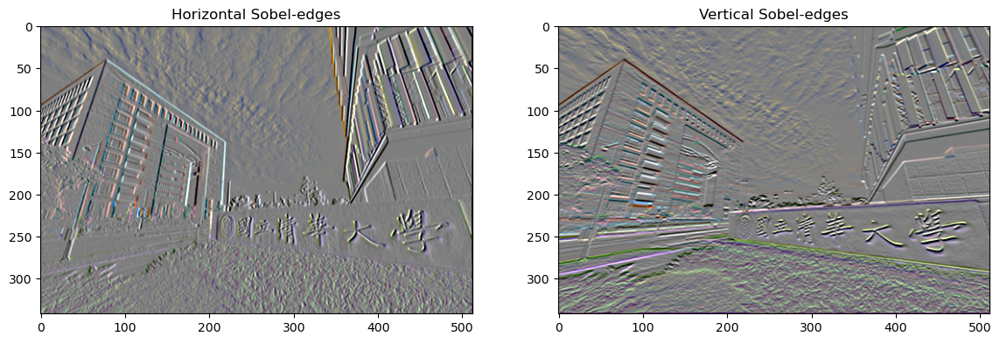

In [151]:
plt.figure(figsize=(14, 10))

sobel = sobel_edges(content_image.to(device))
plt.subplot(1, 2, 1)
imshow(clip_0_1(sobel[..., 0] / 4 + 0.5), 'Horizontal Sobel-edges')
plt.subplot(1, 2, 2)
imshow(clip_0_1(sobel[..., 1] / 4 + 0.5), 'Vertical Sobel-edges')

In [127]:
def total_variation_loss(image):
    '''TODO: implement the total-variation loss yourself -- don't use any
    built-in total-variation function (that's the assignment requirement).
    image: (B, C, H, W) in [0, 1].
    '''
    raise NotImplementedError

<h2 id="Re-run-the-optimization">Re-run the optimization</h2>

In [232]:
total_variation_weight = 1e-3  # Change it as you want

In [233]:
def train_step(image, optimizer):
    optimizer.zero_grad()
    outputs = extractor(image)
    loss = style_content_loss(outputs)
    loss = loss + total_variation_weight * total_variation_loss(image)
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        image.copy_(clip_0_1(image))

In [234]:
image = content_image.clone().to(device).requires_grad_(True)
opt = torch.optim.Adam([image], lr=0.02, betas=(0.99, 0.999), eps=1e-1)

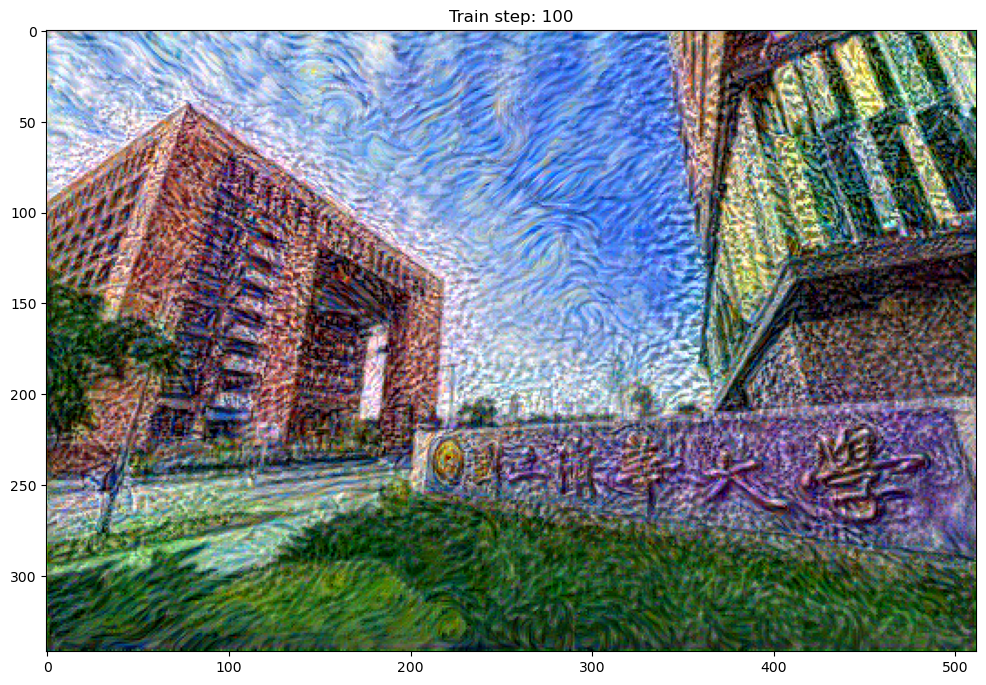

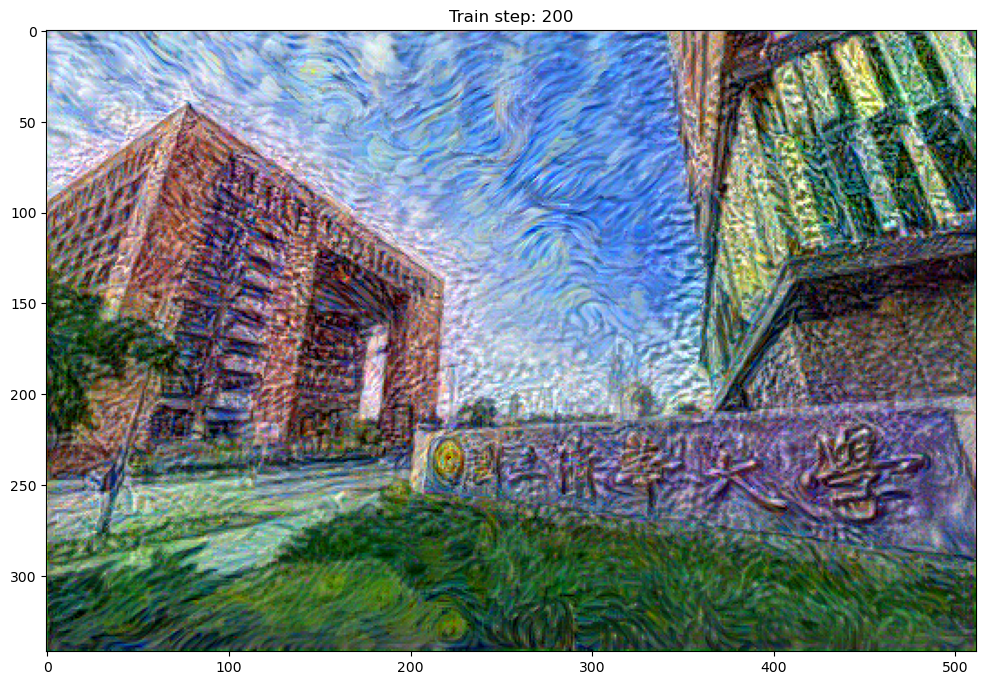

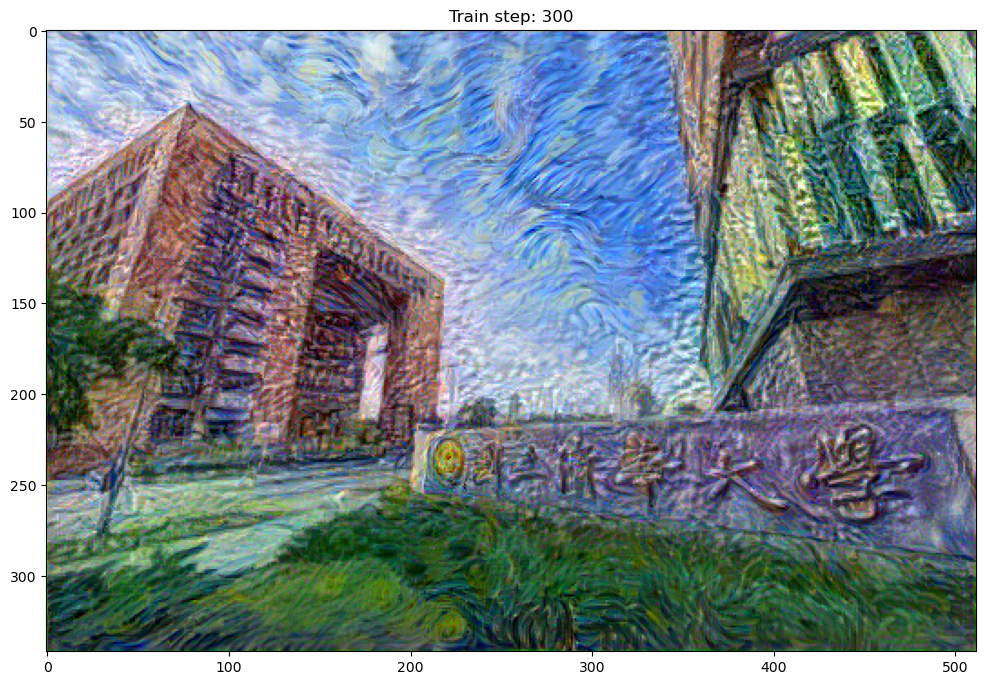

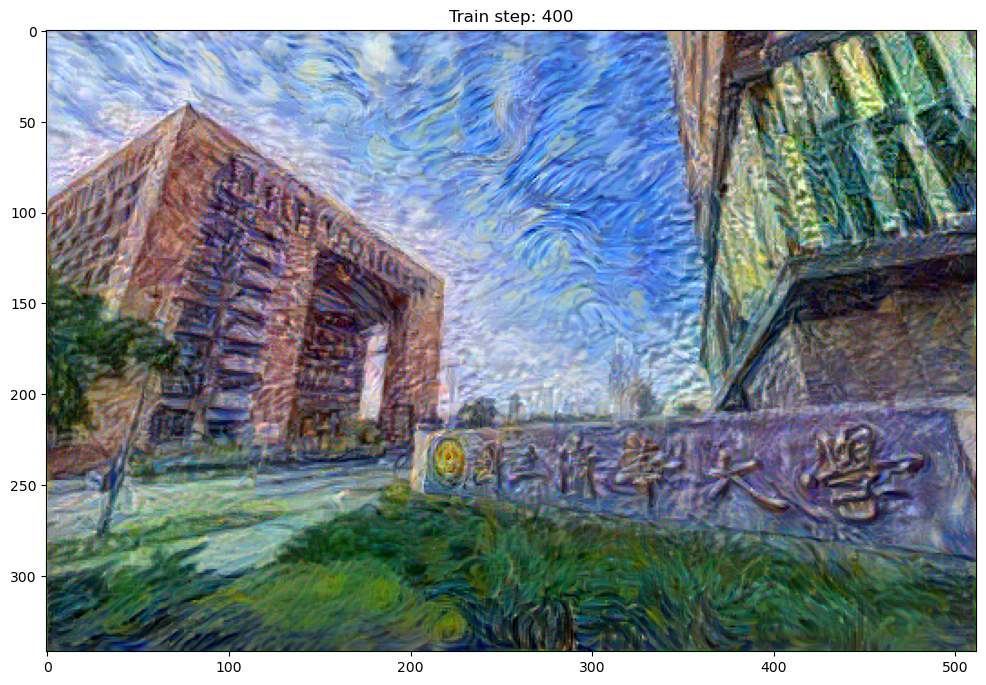

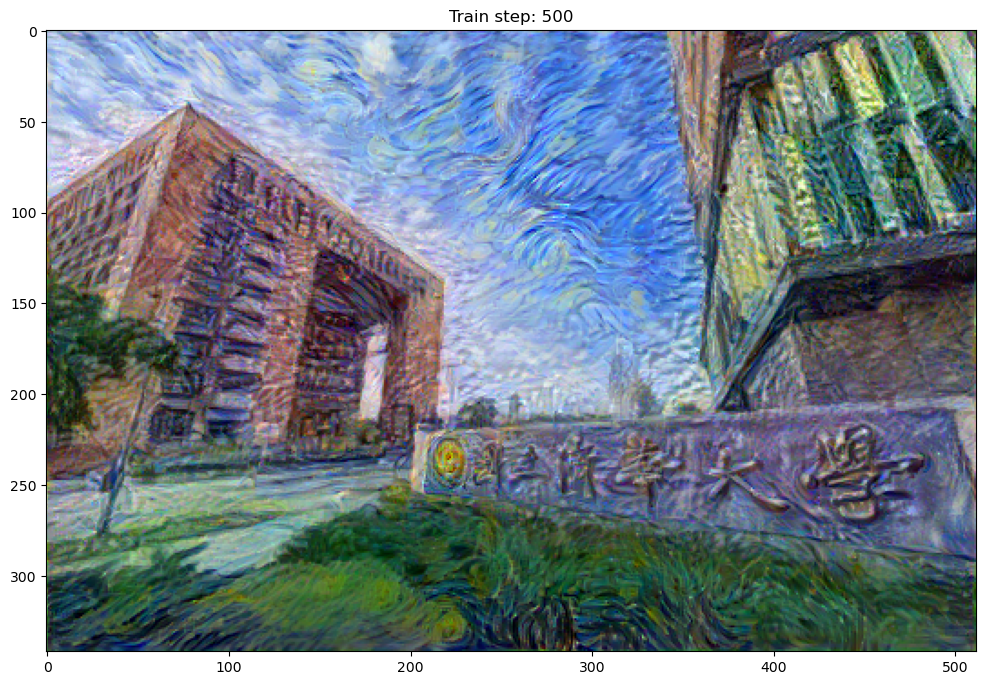

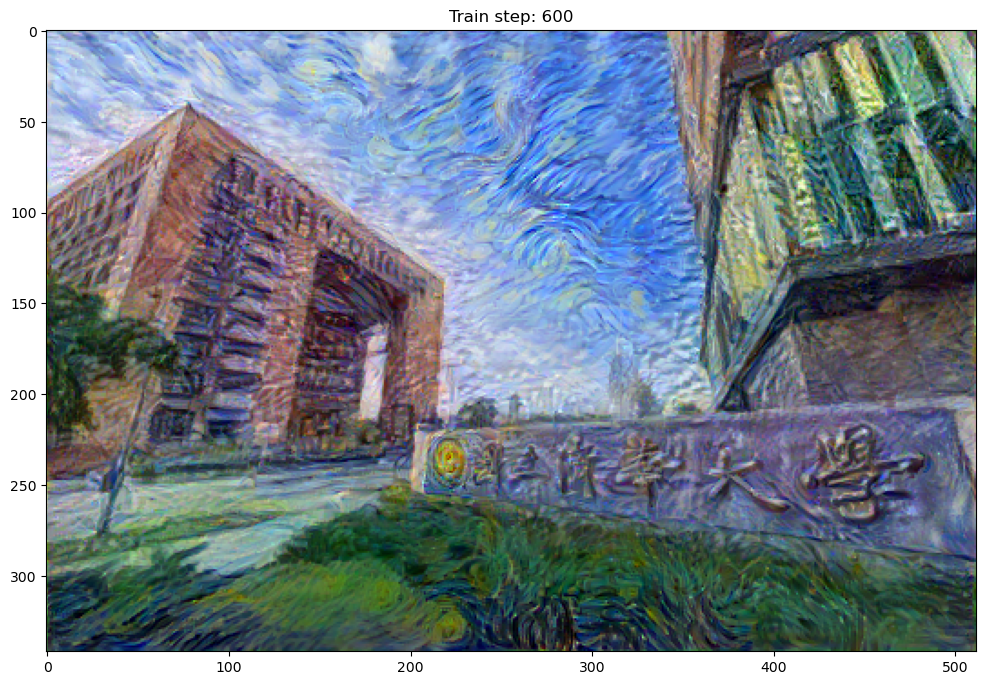

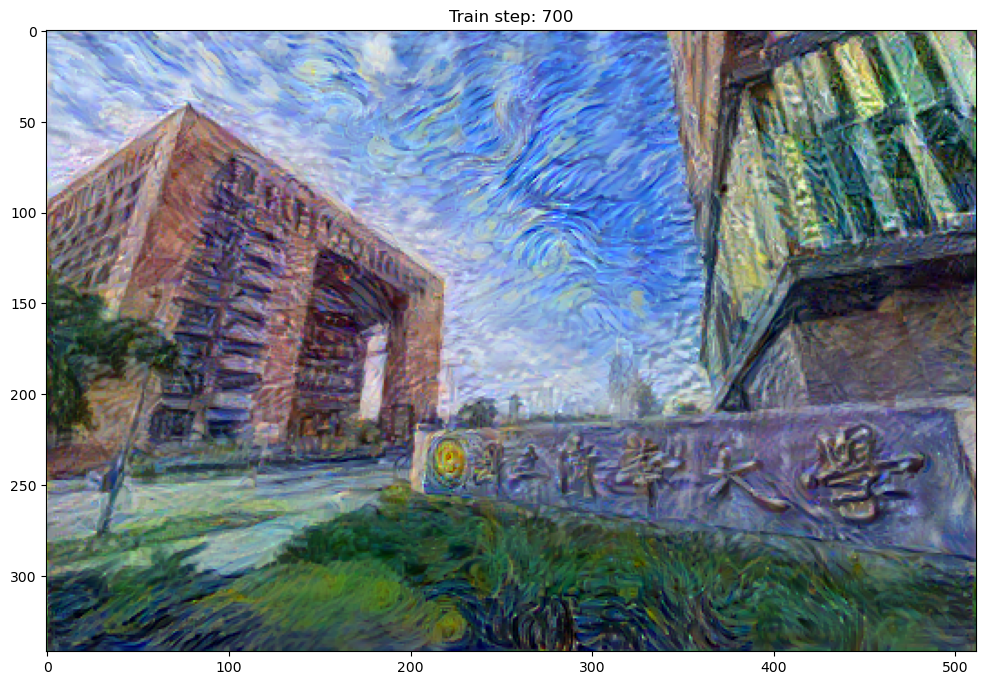

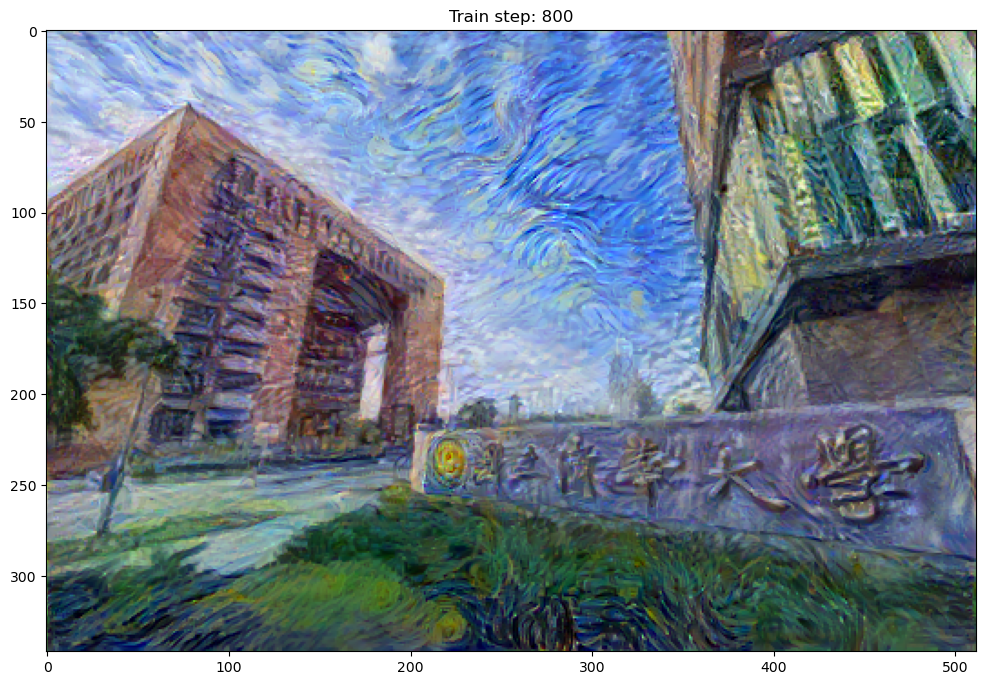

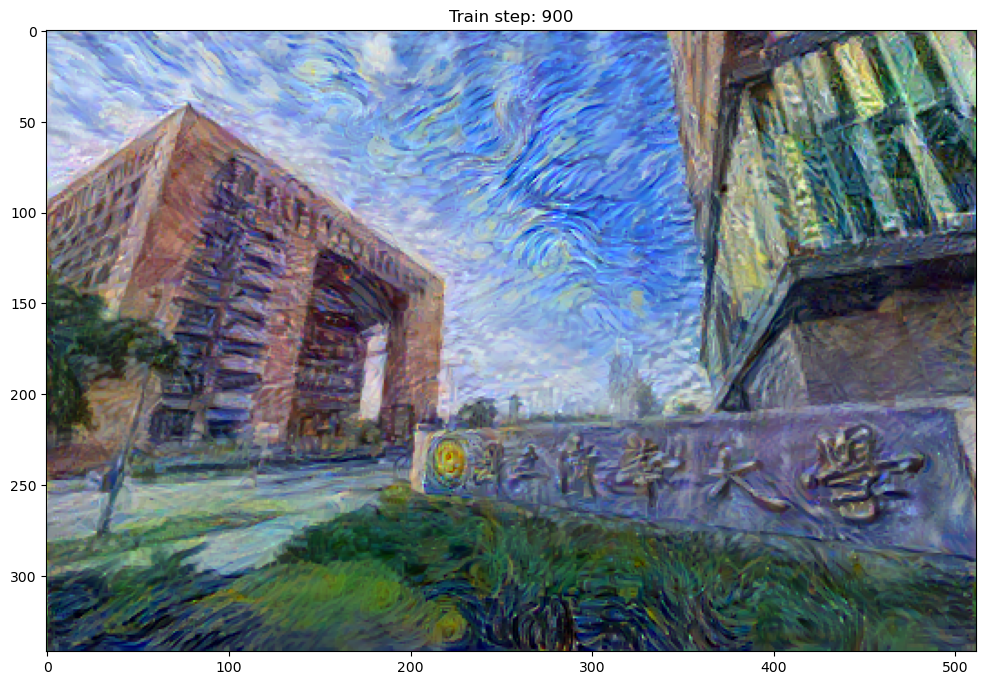

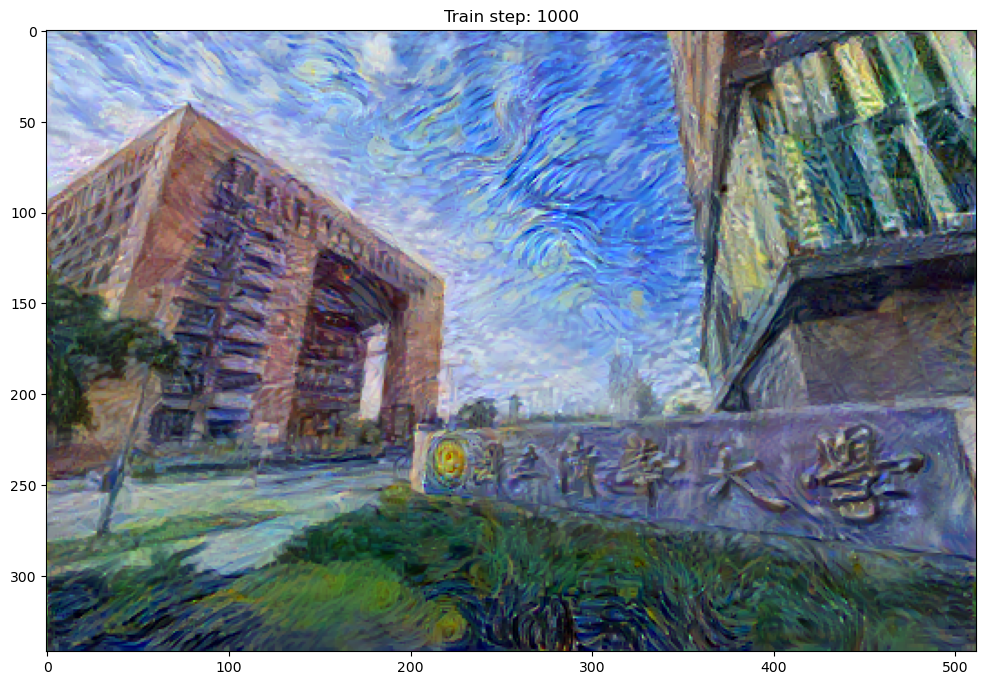

Total time: 27.9


In [235]:
start = time.time()

epochs = 10
steps_per_epoch = 100

step = 0
for n in range(epochs):
    for m in range(steps_per_epoch):
        step += 1
        train_step(image, opt)
    imshow(image)
    plt.title('Train step: {}'.format(step))
    plt.show()

end = time.time()
print('Total time: {:.1f}'.format(end - start))

In [237]:
file_name = './dataset/style_transfer_nthu_starry_night.png'
mpl.image.imsave(file_name, image[0].permute(1, 2, 0).detach().cpu().clamp(0, 1).numpy())

<p>With total variational loos, the image has better quality and looks really like a masterpiece of Vincent van Gogh, right?</p>
<img alt="No description has been provided for this image" src="./dataset/style_transfer_nthu_starry_night.png"/>

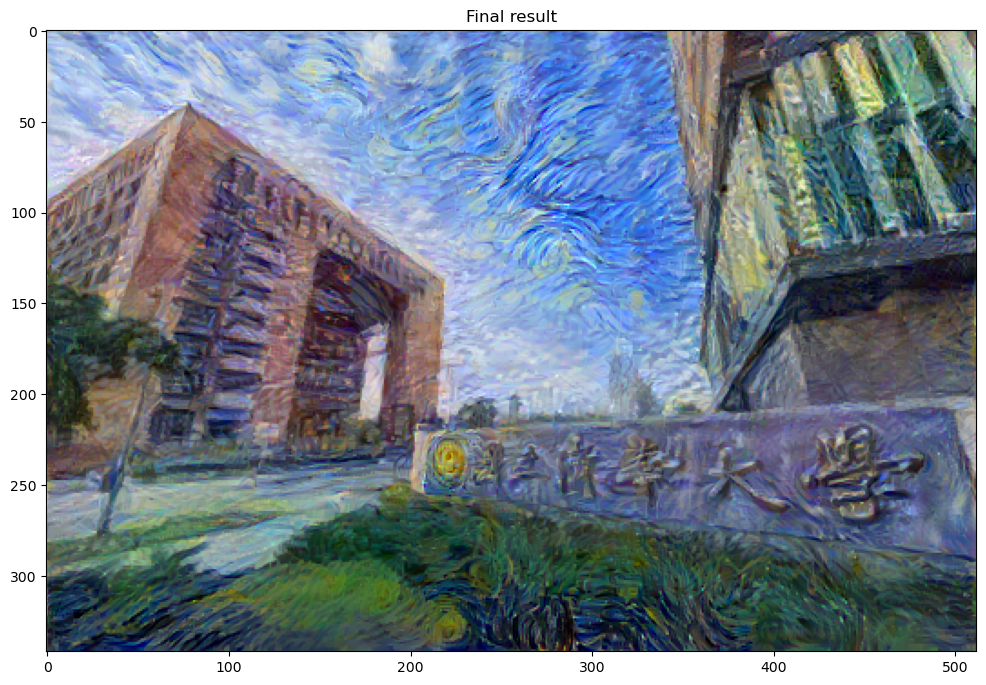

In [236]:
imshow(image)
plt.title('Final result')
plt.show()

<h1><center class="subtitle">AdaIN</center></h1>

<p>The method we mentioned above requires a slow iterative optimization process, which limits its pratical application. Xun Huang and Serge Belongie from Cornell University propose another framework, which enables arbitrary style tranfer in real-time, known as <a href="https://arxiv.org/abs/1703.06868">"Arbitrary Style Transfer in Real-time with Adaptive Instance Normalization"</a>.</p>
<p>AdaIN can transfer arbitrary new styles in real-time, combining the flexibility of the optimization-based framework and the speed similar to the fastest feed-forward approaches. At the heart of this method is a novel Adaptive Instance Normalization (AdaIN) layer aligning the mean and variance of the content features with those of the style features. Instance normalization performs style normalization by normalizing feature statistics, which have been found to carry the style information of an image in the earlier works. A decoder network is then learned to generate the final stylized image by inverting the AdaIN output back to the image space.</p>
<img alt="No description has been provided for this image" src="./figs/adain.png" width="600"/>

In [4]:
CONTENT_DIRS = ['./dataset/mscoco/test2014']
STYLE_DIRS = ['./dataset/wikiart/test']

IMG_SHAPE = (3, 224, 224)  # training image shape, (c, h, w) -- channels-first
SHUFFLE_BUFFER = 1000  # kept only for reference; DataLoader(shuffle=True) shuffles
                        # the whole dataset each epoch, no buffer size needed
BATCH_SIZE = 32
EPOCHS = 30
STEPS_PER_EPOCH = 12000 // BATCH_SIZE

<p>Here we use <a href="http://cocodataset.org/#home">MSCOCO 2014</a> testing dataset as our content dataset, while using <a href="https://www.wikiart.org/">WikiArt</a> testing dataset as style dataset, containing 40,736 and 23,585 images respectively. To prevent from misunderstanding, we have to clarify the reason to use testing dataset instead of training dataset. The size of whole MSCOCO 2014 and WikiArt is more than 45G, which might be too heavy for this tutorial. In addition, our purpose is to train an style transfer model rather than image classification or object detection, thus using testing dataset is nothing to worry about.</p>

Sampled content images:


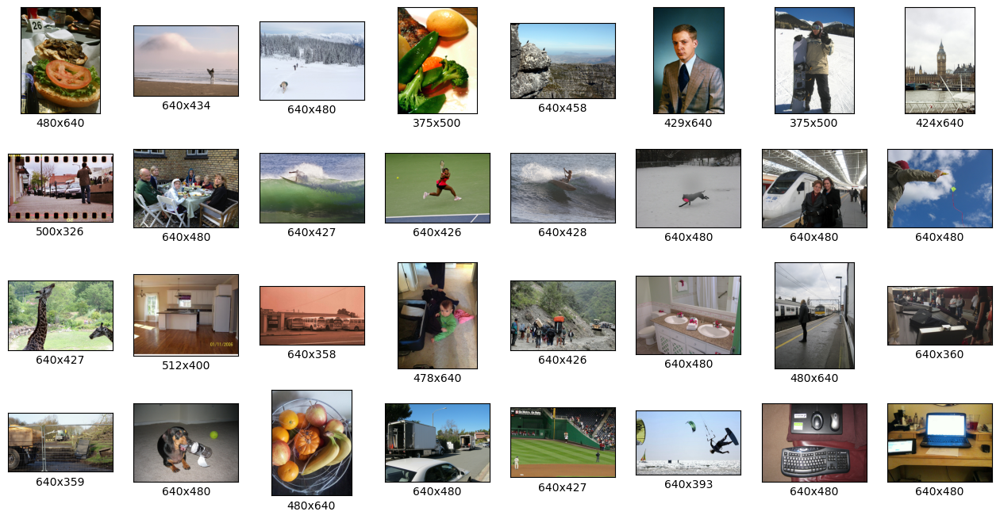

Sampled style images:


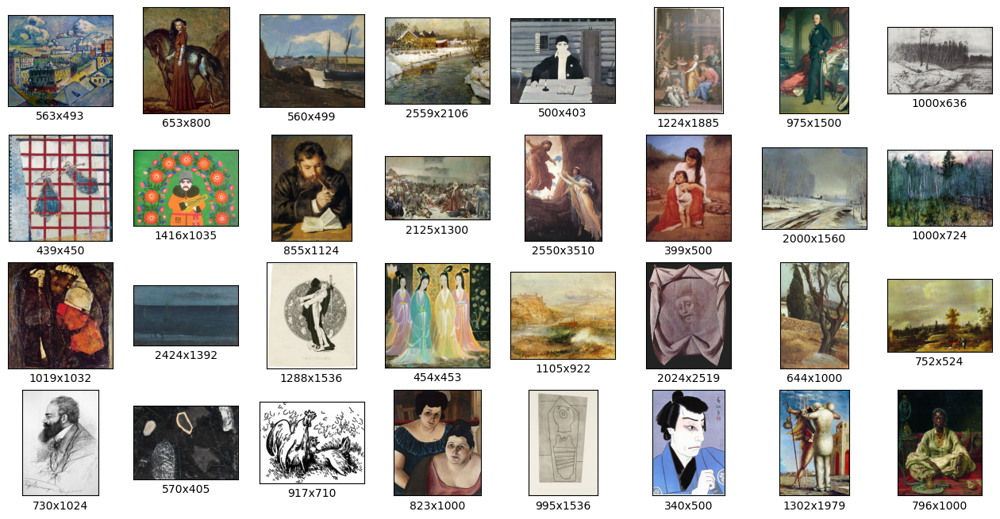

In [5]:
def sample_files(dir, num, pattern='**/*.jpg'):
    '''Samples files in a directory using reservoir sampling.'''
    paths = Path(dir).glob(pattern)
    sampled = []
    for i, path in enumerate(paths):
        if i < num:
            sampled.append(path)
        else:
            s = random.randint(0, i)
            if s < num:
                sampled[s] = path
    return sampled

def plot_images(dir, row, col, pattern):
    paths = sample_files(dir, row * col, pattern)

    plt.figure(figsize=(2 * col, 2 * row))
    for i in range(row * col):
        im = Image.open(paths[i])
        w, h = im.size

        plt.subplot(row, col, i + 1)
        plt.imshow(im)
        plt.grid(False)
        plt.xticks([])
        plt.yticks([])
        plt.xlabel(f'{w}x{h}')
    plt.show()

print('Sampled content images:')
plot_images(CONTENT_DIRS[0], 4, 8, pattern='*.jpg')

print('Sampled style images:')
plot_images(STYLE_DIRS[0], 4, 8, pattern='*.jpg')

<h2 id="Dataset-API">Dataset API</h2>

<p>Before creating dataset API, first we have to remove some unwanted data, such as small images or grayscale images.</p>

In [240]:
def clean(dir_path, min_shape=None):
    paths = Path(dir_path).glob('**/*.jpg')
    deleted = 0
    for path in paths:
        try:
            # Make sure we can decode the image
            im = Image.open(path)
            im.load()

            # Remove grayscale images
            if im.mode != 'RGB' or len(im.getbands()) < 3:
                path.unlink()
                deleted += 1
                continue

            # Remove small images
            if min_shape is not None:
                w, h = im.size
                if h < min_shape[0] or w < min_shape[1]:
                    path.unlink()
                    deleted += 1
        except Exception:
            path.unlink()
            deleted += 1
    return deleted

for dir in CONTENT_DIRS:
    deleted = clean(dir)
print(f'#Deleted content images: {deleted}')

for dir in STYLE_DIRS:
    deleted = clean(dir)
print(f'#Deleted style images: {deleted}')

#Deleted content images: 0


/home/bigboss/miniforge3/envs/dl_2026/lib/python3.13/site-packages/PIL/Image.py:3578: DecompressionBombWarning: Image size (133026477 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


#Deleted style images: 31


<p>VGG19 was trained by Caffe which converted images from RGB to BGR, then zero-centered each color channel with respect to the ImageNet dataset, without scaling. Therefore, we have to do the same thing during data preprocessing.</p>

In [6]:
IMG_MEANS = torch.tensor([103.939, 116.779, 123.68])  # BGR, VGG19/Caffe convention

def preprocess_image(path, init_shape=(448, 448)):
    image = Image.open(path).convert('RGB').resize(init_shape[::-1])
    image = transforms.functional.to_tensor(image) * 255.0  # (3, H, W), 0..255, RGB
    image = transforms.RandomCrop(IMG_SHAPE[1:])(image)

    # Convert image from RGB to BGR, then zero-center each color channel with
    # respect to the ImageNet dataset, without scaling.
    image = image.flip(0)  # RGB -> BGR (flip channel dim)
    image = image - IMG_MEANS.view(3, 1, 1)  # BGR means
    return image

def np_image(image):
    image = image + IMG_MEANS.to(image.device).view(3, 1, 1)  # BGR means
    image = image.flip(0)  # BGR -> RGB
    image = image.clamp(0, 255).byte()
    return image.permute(1, 2, 0).cpu().numpy()

In [7]:
class ContentStyleDataset(Dataset):
    def __init__(self, content_paths, style_paths, preprocess_content=preprocess_image,
                 preprocess_style=None):
        self.content_paths = content_paths
        self.style_paths = style_paths
        self.preprocess_content = preprocess_content
        self.preprocess_style = preprocess_style or preprocess_image

    def __len__(self):
        # one "epoch" = STEPS_PER_EPOCH batches, same as the original
        return STEPS_PER_EPOCH * BATCH_SIZE

    def __getitem__(self, idx):
        c_path = self.content_paths[idx % len(self.content_paths)]
        s_path = self.style_paths[random.randrange(len(self.style_paths))]
        return self.preprocess_content(c_path), self.preprocess_style(s_path)

def build_dataset():
    c_paths = []
    for c_dir in CONTENT_DIRS:
        c_paths += Path(c_dir).glob('*.jpg')
    c_paths = [str(p.resolve()) for p in c_paths]
    s_paths = []
    for s_dir in STYLE_DIRS:
        s_paths += Path(s_dir).glob('*.jpg')
    s_paths = [str(p.resolve()) for p in s_paths]
    print(f'Building dataset from {len(c_paths):,} content images and {len(s_paths):,} style images... ', end='')

    dataset = ContentStyleDataset(c_paths, s_paths)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=4, pin_memory=torch.cuda.is_available())
    print('done')
    return loader

Building dataset from 40,736 content images and 23,554 style images... done
Content batch shape: (32, 3, 224, 224)
Style batch shape: (32, 3, 224, 224)


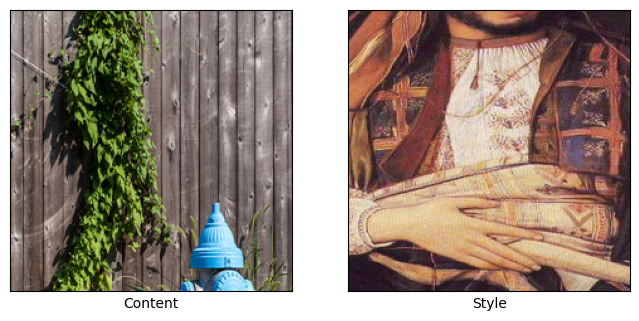

In [8]:
loader = build_dataset()
c_batch, s_batch = next(iter(loader))
c_batch, s_batch = c_batch.to(device), s_batch.to(device)

print('Content batch shape:', tuple(c_batch.shape))
print('Style batch shape:', tuple(s_batch.shape))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(np_image(c_batch[0]))
plt.grid(False)
plt.xticks([])
plt.yticks([])
plt.xlabel('Content')

plt.subplot(1, 2, 2)
plt.imshow(np_image(s_batch[0]))
plt.grid(False)
plt.xticks([])
plt.yticks([])
plt.xlabel('Style')

plt.show()

<h2 id="Adaptive-Instance-Normalization">Adaptive Instance Normalization</h2>

<p>AdaIN recieves a content input $x$ and style input $y$, and simply aligns the channelwise mean and variance of $x$ to match those of $y$. It is worth knowning that unlike BN(Batch Normalization), IN(Instance Normalization) or CIN(Conditional Instance Normalization), AdaIN has no learnable affine parameters. Instead, it adaptively computes the affine parameters from the style input:</p>

<center class="formula">$\text{AdaIN}(x,\,y) = \sigma(y)\,(\cfrac{x - \mu(x)}{\sigma(x)}) + \mu(y)$</center>

In [ ]:
class AdaIN(nn.Module):
    epsilon = 1e-5

    def forward(self, content_feat, style_feat):
        '''TODO: implement Adaptive Instance Normalization.
        content_feat, style_feat: (B, C, H, W) VGG feature maps.
        AdaIN(x, y) = sigma(y) * (x - mu(x)) / sigma(x) + mu(y)
        where mu/sigma are computed per-sample, per-channel (i.e. over the
        H, W spatial dimensions -- the same statistics Instance Norm uses).
        '''
        raise NotImplementedError

<h2 id="Model">Model</h2>

<p>We use the first few layers of a fixed VGG-19 network to encode the content and style images. An AdaIN layer is used to perform style transfer in the feature space. A decoder is learned to invert the AdaIN output to the image spaces. Moreover, we use the same VGG encoder to compute a content loss $L_c$ and style loss $L_s$. Here we define $t$ as the output of AdaIN layer.</p>
<center class="formula">$t = \text{AdaIN}(f(c),\,f(s))$.</center>
<br/>
<p>Next, we can define the loss function which is composed of content loss and style loss, where $\lambda$ is weighting factor.</p>
<center class="formula">$L = L_c + \lambda L_s$.</center>
<br/>
<p>The content loss is the Euclidean distance between the target features and the features of the output image. We use the AdaIN output $t$ as the content target, instead of the commonly used feature responses of the content image. The author found this leads to slightly faster convergence and also aligns with our goal of inverting the AdaIN output $t$.</p>
<center class="formula">$L_c = \|\,f(g(t)) - t\,\|_2$</center>
<br/>
<p>Since AdaIN layer only transfers the mean and standard deviation of the style features, our style loss only matches these statistics. Although we find the commonly used Gram matrix loss can produce similar results, we match the IN statistics because it is conceptually cleaner. This style loss has also been explored by <a href="https://arxiv.org/pdf/1701.01036.pdf">Li et al</a>.</p>
<center class="formula">$L_s = \sum\limits_{i=1}^{L}\|\,\mu(\phi_i(g(t)))-\mu(\phi_i(s))\,\|_2 + \sum\limits_{i=1}^{L}\|\,\sigma(\phi_i(g(t)))-\sigma(\phi_i(s))\,\|_2$</center>
<ul>
<li>$c$ represents content while $s$ represents style</li>
<li>$t$ is the output of AdaIN layer</li>
<li>$f$ is encoder</li>
<li>$g$ is decoder</li>
<li>$\phi_i$ denotes a layer in VGG-19 used to compute the style loss</li>
</ul>

In [10]:
class AdaINDecoder(nn.Module):
    """Mirrors `ArbitraryStyleTransferNet.declare_decoder()`: Keras'
    Conv2DTranspose(..., padding='same') with stride 1 is just a same-shape
    conv -- nn.ConvTranspose2d(..., padding=1) with stride 1 and a 3x3 kernel
    matches it; UpSampling2D(2) (nearest-neighbor by default) is nn.Upsample.
    """
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.ConvTranspose2d(256, 256, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(256, 256, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(256, 256, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.ConvTranspose2d(128, 128, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.ConvTranspose2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 3, 3, padding=1),
        )

    def forward(self, x):
        return self.net(x)


class ArbitraryStyleTransferNet(nn.Module):
    CONTENT_LAYER = 'block4_conv1'
    STYLE_LAYERS = ('block1_conv1', 'block2_conv1', 'block3_conv1', 'block4_conv1')

    def __init__(self, content_loss_weight=1, style_loss_weight=10):
        super().__init__()
        self.content_loss_weight = content_loss_weight
        self.style_loss_weight = style_loss_weight

        indices = [VGG19_LAYER_INDEX[self.CONTENT_LAYER]] + \
                  [VGG19_LAYER_INDEX[n] for n in self.STYLE_LAYERS]
        self.vgg19_extractor = VggIntermediateLayers(indices)

        self.adain = AdaIN()
        self.decoder = AdaINDecoder()

        # populated on each forward() call, the PyTorch stand-in for Keras'
        # self.add_loss(...) side-channel
        self.content_loss = None
        self.style_loss = None

    def forward(self, inputs):
        c_batch, s_batch = inputs

        c_enc = self.vgg19_extractor(vgg19_preprocess(c_batch))
        c_enc_c = c_enc[0]

        s_enc = self.vgg19_extractor(vgg19_preprocess(s_batch))
        s_enc_c = s_enc[0]
        s_enc_s = s_enc[1:]

        # normalized_c is the output of the AdaIN layer
        normalized_c = self.adain(c_enc_c, s_enc_c)
        output = self.decoder(normalized_c)

        # Calculate loss
        out_enc = self.vgg19_extractor(vgg19_preprocess(output))
        out_enc_c = out_enc[0]
        out_enc_s = out_enc[1:]

        self.content_loss = self.content_loss_weight * F.mse_loss(out_enc_c, normalized_c)

        style_loss = out_enc_c.new_zeros(())
        for o, s in zip(out_enc_s, s_enc_s):
            o_mean, o_var = o.mean([2, 3], keepdim=True), o.var([2, 3], unbiased=False, keepdim=True)
            o_std = (o_var + self.adain.epsilon).sqrt()

            s_mean, s_var = s.mean([2, 3], keepdim=True), s.var([2, 3], unbiased=False, keepdim=True)
            s_std = (s_var + self.adain.epsilon).sqrt()

            style_loss = style_loss + F.mse_loss(o_mean, s_mean) + F.mse_loss(o_std, s_std)
        self.style_loss = self.style_loss_weight * style_loss

        # Return losses explicitly so DataParallel can gather them across GPUs
        return output, c_enc_c, normalized_c, out_enc_c, self.content_loss, self.style_loss

In [11]:
# Plot results
def plot_outputs(outputs, captions=None, col=5):
    row = len(outputs)
    plt.figure(figsize=(3 * col, 3 * row))
    for i in range(col):
        for j in range(row):
            plt.subplot(row, col, j * col + i + 1)
            plt.imshow(np_image(outputs[j][i, :3]))
            plt.grid(False)
            plt.xticks([])
            plt.yticks([])
            if captions is not None:
                plt.xlabel(captions[j])
    plt.show()

In [25]:
loader = build_dataset()
model = ArbitraryStyleTransferNet().to(device)

c_batch, s_batch = next(iter(loader))
c_batch, s_batch = c_batch.to(device), s_batch.to(device)
print(f'Input shape: ({tuple(c_batch.shape)}, {tuple(s_batch.shape)})')
output, *_ = model((c_batch, s_batch))
print(f'Output shape: {tuple(output.shape)}')
print(f'Init. content loss: {model.content_loss.item():,.2f}, style loss: {model.style_loss.item():,.2f}')
print(model)

Building dataset from 40,736 content images and 23,554 style images... done
Input shape: ((32, 3, 224, 224), (32, 3, 224, 224))
Output shape: (32, 3, 224, 224)
Init. content loss: 3,910,611.50, style loss: 40,197,512.00
ArbitraryStyleTransferNet(
  (vgg19_extractor): VggIntermediateLayers(
    (backbone): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

<h2 id="Training">Training</h2>

In [26]:
# Train the model
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

CKP_DIR = 'checkpoints'
os.makedirs(CKP_DIR, exist_ok=True)
init_epoch = 1

ckpts = sorted(Path(CKP_DIR).glob('ckpt_*.pt'), key=lambda p: int(p.stem.split('_')[-1]))
if ckpts:
    latest = ckpts[-1]
    checkpoint = torch.load(latest, map_location=device)
    model.load_state_dict(checkpoint['model'])
    optimizer.load_state_dict(checkpoint['optimizer'])
    init_epoch = checkpoint['epoch'] + 1
    print(f'Resume training from epoch {init_epoch - 1}')

# Wrap with DataParallel after loading checkpoint so saved weights stay compatible
if torch.cuda.device_count() > 1:
    print(f'Using {torch.cuda.device_count()} GPUs with DataParallel')
    model = nn.DataParallel(model)

Using 4 GPUs with DataParallel


In [27]:
def train_step(inputs):
    optimizer.zero_grad()
    _, _, _, _, c_loss, s_loss = model(inputs)
    # .mean() aggregates the per-GPU loss scalars gathered by DataParallel
    loss = c_loss.mean() + s_loss.mean()
    loss.backward()
    optimizer.step()
    return c_loss.mean().item(), s_loss.mean().item()

In [28]:
def train(loader, init_epoch):
    for epoch in range(init_epoch, EPOCHS + 1):
        print(f'Epoch {epoch:>2}/{EPOCHS}')
        c_loss_sum, s_loss_sum = 0.0, 0.0
        for step, (c_batch, s_batch) in enumerate(loader):
            if step >= STEPS_PER_EPOCH:
                break
            c_batch, s_batch = c_batch.to(device), s_batch.to(device)
            c_loss, s_loss = train_step((c_batch, s_batch))
            c_loss_sum += c_loss
            s_loss_sum += s_loss
            n = step + 1
            print(f'{n:>5}/{STEPS_PER_EPOCH} - loss: {(c_loss_sum+s_loss_sum)/n:,.2f} '
                  f'- content loss: {c_loss_sum/n:,.2f} - style loss: {s_loss_sum/n:,.2f}', end='\r')

        print()
        _state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
        torch.save({'model': _state, 'optimizer': optimizer.state_dict(),
                    'epoch': epoch}, os.path.join(CKP_DIR, f'ckpt_{epoch}.pt'))

        with torch.no_grad():
            output, c_enc_c, normalized_c, out_enc_c, _, _ = model((c_batch, s_batch))
        plot_outputs((s_batch, c_batch, output, c_enc_c, normalized_c, out_enc_c),
                     ('Style', 'Content', 'Trans', 'Content Enc', 'Normalized', 'Trans Enc'))

In [ ]:
train(loader, init_epoch)

<h2 id="Testing">Testing</h2>

Recovered loss: 4869320.5


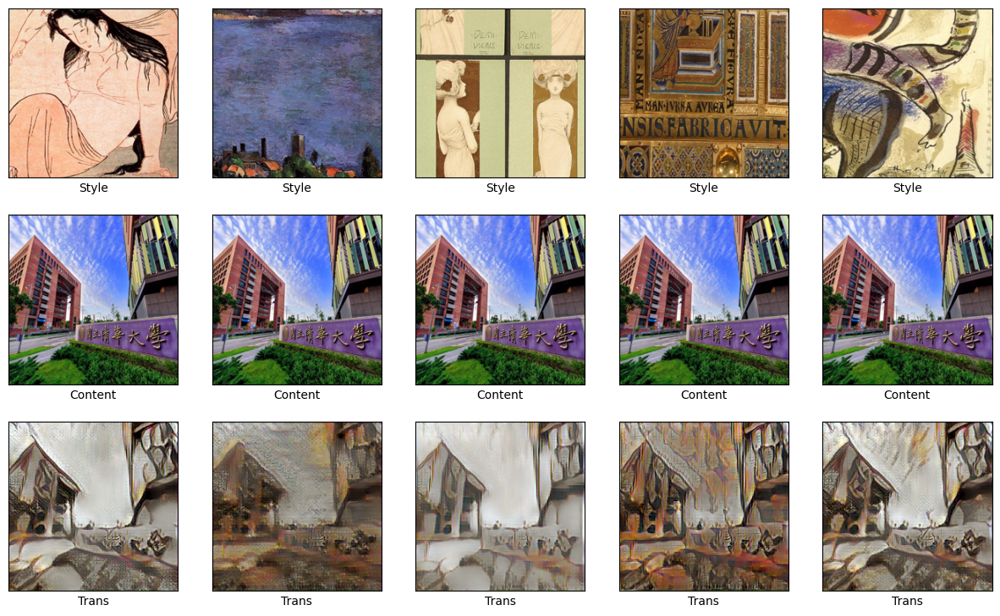

Recovered loss: 3167962.5


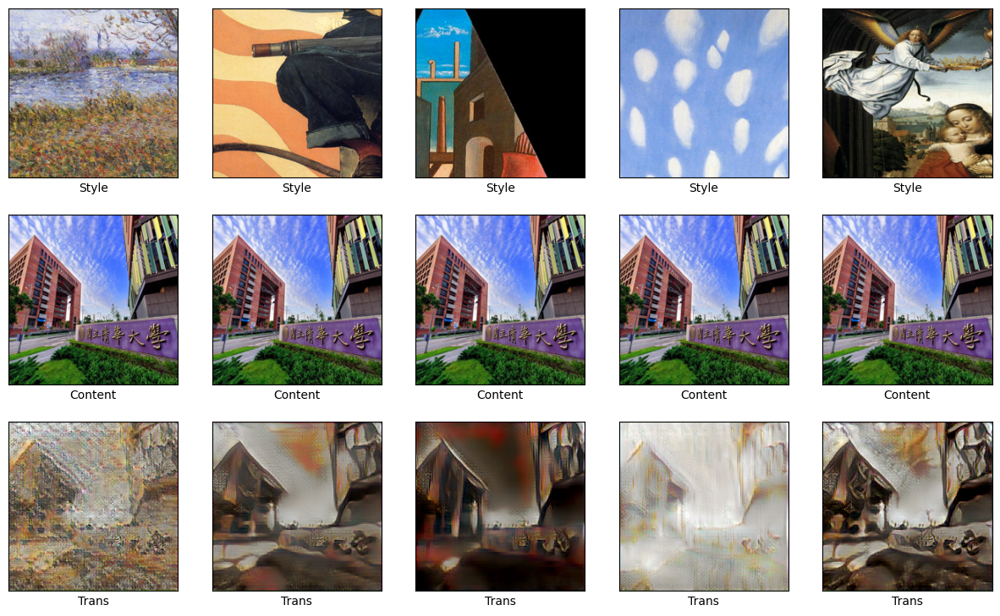

In [35]:
CKP_PATH = 'checkpoints/ckpt_20.pt'

model = ArbitraryStyleTransferNet().to(device)
checkpoint = torch.load(CKP_PATH, map_location=device)
model.load_state_dict(checkpoint['model'])
model.eval()

loader = build_dataset()

with torch.no_grad():
    for idx, (c_batch, s_batch) in enumerate(loader):
        if idx > 1:
            break
        c_batch, s_batch = c_batch.to(device), s_batch.to(device)
        output, c_enc_c, normalized_c, out_enc_c, c_loss, s_loss = model((c_batch, s_batch))
        print('Recovered loss:', (c_loss.mean() + s_loss.mean()).item())

        plot_outputs((s_batch, c_batch, output), ('Style', 'Content', 'Trans'))

<h2 id="NTHU-Example">NTHU Example</h2>

<p>One of the most important advantages of AdaIN is speed. Earlier we have implemented iterative style transfer, which takes roughly 30 seconds per image on Nvidia GeForce RTX 2080Ti, meanwhile AdaIN is up to three orders of magnitude faster than the former. Here we demostrate the power of AdaIN with single content and 25 distinct styles.</p>

In [30]:
def preprocess_example(path, init_shape=(IMG_SHAPE[1], IMG_SHAPE[2])):
    image = Image.open(path).convert('RGB').resize(init_shape[::-1])
    image = transforms.functional.to_tensor(image) * 255.0

    # Convert image from RGB to BGR, then zero-center each color channel with
    # respect to the ImageNet dataset, without scaling.
    image = image.flip(0)  # RGB -> BGR
    image = image - IMG_MEANS.view(3, 1, 1)
    return image

def nthu_example():
    c_paths = ['./dataset/content_nthu.jpg']

    s_paths = []
    for s_dir in STYLE_DIRS:
        s_paths += Path(s_dir).glob('*.jpg')
    s_paths = [str(p.resolve()) for p in s_paths]
    print(f'Building dataset from {len(c_paths):,} content images and {len(s_paths):,} style images... ', end='')

    dataset = ContentStyleDataset(c_paths, s_paths, preprocess_content=preprocess_example,
                                   preprocess_style=preprocess_image)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
    print('done')
    return loader

Building dataset from 1 content images and 23,554 style images... done


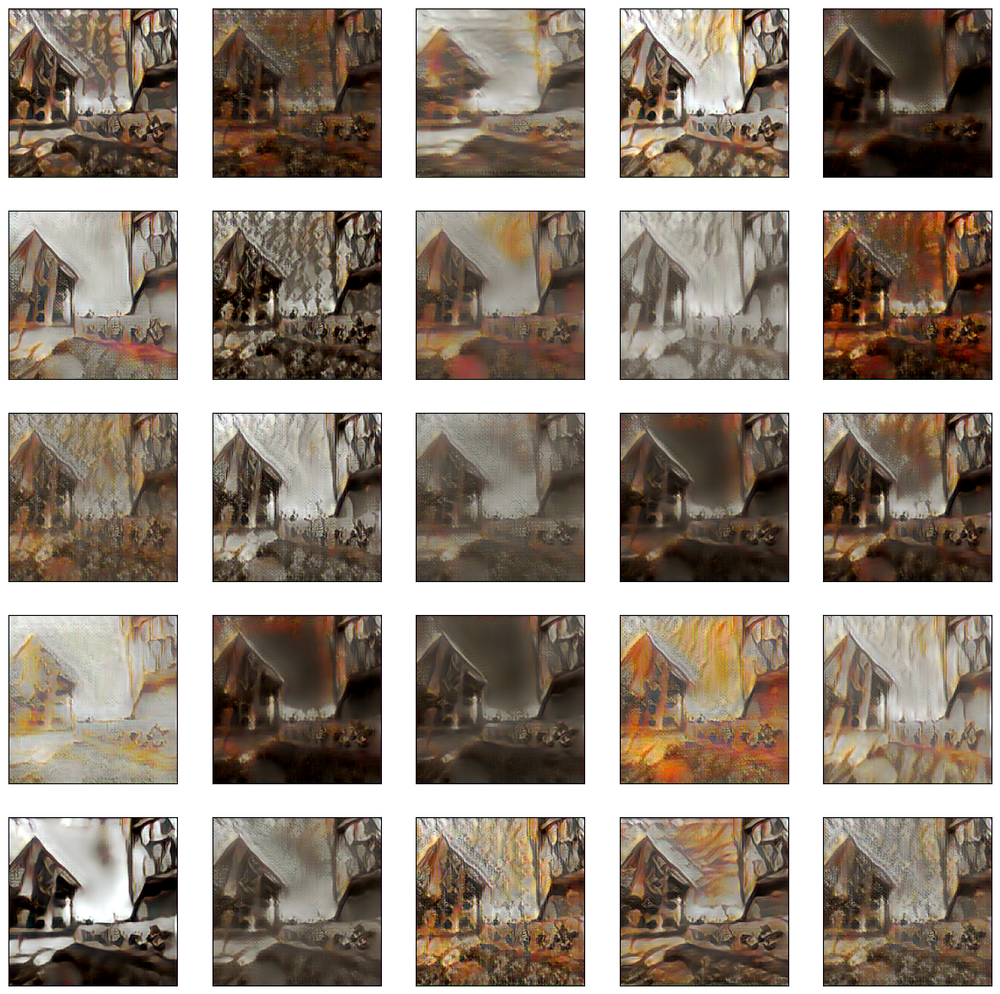

In [32]:
loader = nthu_example()
outputs = []

with torch.no_grad():
    for idx, (c_batch, s_batch) in enumerate(loader):
        if idx > 4:
            break
        c_batch, s_batch = c_batch.to(device), s_batch.to(device)
        output, c_enc_c, normalized_c, out_enc_c,_,_ = model((c_batch, s_batch))
        outputs.append(output)

plot_outputs(outputs)

<h1 id="Save-and-Load-Models"><center>Save and Load Models</center></h1>

<p>Model progress can be saved during and after training. This means a model can resume where it left off and avoid long training times. Saving also means you can share your model and others can recreate your work. When publishing research models and techniques, most machine learning practitioners share:</p>
<ul><li>code to create the model, and</li><li>the trained weights, or parameters, for the model</li></ul>
<p>Sharing this data helps others understand how the model works and try it themselves with new data.</p>
<p>Unlike TensorFlow -- which distinguishes <b>Checkpoints</b> (just the parameter values, via <code>Model.save_weights</code> / <code>tf.train.Checkpoint</code>) from the <b>SavedModel</b> format (parameters + a serialized description of the computation, for deployment to TF Serving/TFLite/TF.js/other languages) -- PyTorch has **one** standard mechanism: <code>torch.save</code>/<code>torch.load</code> on a plain Python object (usually a <code>dict</code>). What you put in that dict is up to you -- just the model's <code>state_dict()</code> (weights only, the analogue of <code>Model.save_weights</code>), or model + optimizer + epoch/step (the analogue of <code>tf.train.Checkpoint</code>, letting you resume training exactly). There's no PyTorch-native equivalent of SavedModel's deploy-to-other-languages story -- the closest is exporting to TorchScript or ONNX, which is out of scope here.</p>

<p>For simplicity, here we use <a href="http://yann.lecun.com/exdb/mnist/">MNIST</a> dataset to demonstrate how to save and load wegihts.</p>

In [37]:
_train = torchvision.datasets.MNIST(root='./data', train=True, download=True)
_test  = torchvision.datasets.MNIST(root='./data', train=False, download=True)
train_images, train_labels = _train.data.numpy(), _train.targets.numpy()
test_images,  test_labels  = _test.data.numpy(),  _test.targets.numpy()

train_labels = train_labels[:1000]
test_labels  = test_labels[:1000]

train_images = train_images[:1000].reshape(-1, 28 * 28) / 255.0
test_images  = test_images[:1000].reshape(-1, 28 * 28) / 255.0

In [38]:
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.d1 = nn.Linear(28 * 28, 128)
        self.dropout = nn.Dropout(0.2)
        self.d2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.d1(x))
        x = self.dropout(x)
        return self.d2(x)  # logits

In [39]:
model = MyModel().to(device)
print(model)
print('Total params:', sum(p.numel() for p in model.parameters()))

MyModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (d1): Linear(in_features=784, out_features=128, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (d2): Linear(in_features=128, out_features=10, bias=True)
)
Total params: 101770


## Save checkpoints during training
You can use a trained model without having to retrain it, or pick up training where you left off. PyTorch has no built-in training loop or callback system (there's no `Model.fit`), so "the callback that saves periodically" is just... a couple of lines inside your own loop.

## Checkpoint usage

In [40]:
EPOCHS = 5

CKP_DIR_SAVE = './checkpoints_save'
os.makedirs(CKP_DIR_SAVE, exist_ok=True)

def fit(model, X, y, X_val, y_val, epochs, checkpoint_every_epoch=True):
    optimizer = torch.optim.Adam(model.parameters())
    criterion = nn.CrossEntropyLoss()
    X, y = torch.from_numpy(X).float().to(device), torch.from_numpy(y).long().to(device)
    X_val, y_val = torch.from_numpy(X_val).float().to(device), torch.from_numpy(y_val).long().to(device)

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(X), y)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_acc = (model(X_val).argmax(1) == y_val).float().mean().item()
        print(f'Epoch {epoch+1}/{epochs} - loss: {loss.item():.4f} - val_accuracy: {val_acc:.4f}')

        # the equivalent of a `ModelCheckpoint(..., save_weights_only=True, period=1)` callback
        if checkpoint_every_epoch:
            path = os.path.join(CKP_DIR_SAVE, f'ckpt-epoch{epoch+1}.pt')
            torch.save(model.state_dict(), path)
            print('  saved', path)

fit(model, train_images, train_labels, test_images, test_labels, EPOCHS)

Epoch 1/5 - loss: 2.2959 - val_accuracy: 0.2750
  saved ./checkpoints_save/ckpt-epoch1.pt
Epoch 2/5 - loss: 2.2284 - val_accuracy: 0.4550
  saved ./checkpoints_save/ckpt-epoch2.pt
Epoch 3/5 - loss: 2.1605 - val_accuracy: 0.5500
  saved ./checkpoints_save/ckpt-epoch3.pt
Epoch 4/5 - loss: 2.0946 - val_accuracy: 0.5750
  saved ./checkpoints_save/ckpt-epoch4.pt
Epoch 5/5 - loss: 2.0277 - val_accuracy: 0.6040
  saved ./checkpoints_save/ckpt-epoch5.pt


<p>Now rebuild a fresh, untrained model, and evaluate it on the test set. An untrained model will perform at chance levels (~10% accuracy):</p>

In [41]:
# Create a new model instance
model = MyModel().to(device)

In [42]:
@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    X, y = torch.from_numpy(X).float().to(device), torch.from_numpy(y).long().to(device)
    logits = model(X)
    loss = F.cross_entropy(logits, y).item()
    acc = (logits.argmax(1) == y).float().mean().item()
    return loss, acc

# Re-evaluate the model
loss, acc = evaluate(model, test_images, test_labels)
print('Restored model, accuracy: {:5.2f}%'.format(100 * acc))

Restored model, accuracy: 12.30%


<p>Create a new, untrained model. When restoring a model from weights-only, you must have a model with the same architecture as the original model. Since it's the same model architecture, you can share weights despite that it's a different instance of the model.</p>
<p>After loading the weights from the checkpoint, we can re-evaluate the model. As you can see, the accuracy raises up to 85.5%, which is same as the one we have trained earlier.</p>

In [43]:
# Load the previously saved weights
latest = max(Path(CKP_DIR_SAVE).glob('*.pt'), key=os.path.getmtime)
model.load_state_dict(torch.load(latest, map_location=device))

# Re-evaluate the model
loss, acc = evaluate(model, test_images, test_labels)
print('Restored model, accuracy: {:5.2f}%'.format(100 * acc))

Restored model, accuracy: 60.40%


## What are these files?
The above code stores the weights with `torch.save`, PyTorch's own pickle-based binary serialization format -- a single `.pt` file per checkpoint containing the model's `state_dict()` (an `OrderedDict` mapping parameter names to tensors).

## Manually checkpointing model + optimizer
To resume training *exactly* (not just restore the weights), also save the optimizer's state -- this is the PyTorch analogue of `tf.train.Checkpoint`/`CheckpointManager`, which additionally captures "slot variables" like Adam's momentum. In PyTorch there's no separate API for this: `optimizer.state_dict()` already carries the same information, so you save it in the same dict as the model.

In [44]:
train_ds_full = torch.utils.data.TensorDataset(
    torch.from_numpy(train_images).float(), torch.from_numpy(train_labels).long())
test_ds_full = torch.utils.data.TensorDataset(
    torch.from_numpy(test_images).float(), torch.from_numpy(test_labels).long())
train_loader = DataLoader(train_ds_full, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds_full, batch_size=32)

In [45]:
model = MyModel().to(device)
optimizer = torch.optim.Adam(model.parameters())
criterion = nn.CrossEntropyLoss()

In [46]:
def train_step(images, labels):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(images), labels)
    loss.backward()
    optimizer.step()
    return loss.item()

@torch.no_grad()
def test_step(images, labels):
    model.eval()
    logits = model(images)
    loss = criterion(logits, labels).item()
    acc = (logits.argmax(1) == labels).float().mean().item()
    return loss, acc

In [47]:
CKP_PATH = './checkpoints_full.pt'

for epoch in range(EPOCHS):
    train_losses = [train_step(x.to(device), y.to(device)) for x, y in train_loader]
    test_results = [test_step(x.to(device), y.to(device)) for x, y in test_loader]
    test_losses, test_accs = zip(*test_results)

    print('Epoch {:0}, Loss: {:.2f}, Test Loss: {:.2f}, Test Accuracy: {:.2f}'.format(
        epoch + 1, sum(train_losses) / len(train_losses),
        sum(test_losses) / len(test_losses), 100 * sum(test_accs) / len(test_accs)))

    # save model + optimizer + epoch in a single checkpoint file
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'epoch': epoch + 1}, CKP_PATH)
    print('Saved checkpoint for epoch {}: {}'.format(epoch + 1, CKP_PATH))

Epoch 1, Loss: 1.81, Test Loss: 1.37, Test Accuracy: 70.41
Saved checkpoint for epoch 1: ./checkpoints_full.pt
Epoch 2, Loss: 0.90, Test Loss: 0.84, Test Accuracy: 77.05
Saved checkpoint for epoch 2: ./checkpoints_full.pt
Epoch 3, Loss: 0.58, Test Loss: 0.68, Test Accuracy: 79.49
Saved checkpoint for epoch 3: ./checkpoints_full.pt
Epoch 4, Loss: 0.46, Test Loss: 0.59, Test Accuracy: 82.23
Saved checkpoint for epoch 4: ./checkpoints_full.pt
Epoch 5, Loss: 0.37, Test Loss: 0.54, Test Accuracy: 83.40
Saved checkpoint for epoch 5: ./checkpoints_full.pt


In [48]:
# Create a new model instance
model = MyModel().to(device)
optimizer = torch.optim.Adam(model.parameters())

In [49]:
test_results = [test_step(x.to(device), y.to(device)) for x, y in test_loader]
test_losses, test_accs = zip(*test_results)
print('Test Loss: {:.2f}, Test Accuracy: {:.2f}'.format(
    sum(test_losses) / len(test_losses), 100 * sum(test_accs) / len(test_accs)))

Test Loss: 2.31, Test Accuracy: 11.04


After the first evaluation on a fresh, untrained model you can restore the checkpoint and pick up training exactly where you left off:

In [50]:
checkpoint = torch.load(CKP_PATH, map_location=device)
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
print('Resuming from epoch', checkpoint['epoch'])

test_results = [test_step(x.to(device), y.to(device)) for x, y in test_loader]
test_losses, test_accs = zip(*test_results)
print('Test Loss: {:.2f}, Test Accuracy: {:.2f}'.format(
    sum(test_losses) / len(test_losses), 100 * sum(test_accs) / len(test_accs)))

Resuming from epoch 5
Test Loss: 0.54, Test Accuracy: 83.40


For more information about `torch.save`/`torch.load` and general checkpointing recipes, see the [PyTorch Saving and Loading Models guide](https://pytorch.org/tutorials/beginner/saving_loading_models.html).

<h2 id="Reference">Reference</h2>

<ul>
<li><p><a href="https://docs.pytorch.org/vision/stable/models/vgg.html">torchvision VGG models</a>.</p></li>
<li><p>The code of style transfer is based on the <a href="https://www.tensorflow.org/tutorials/generative/style_transfer">TensorFlow official tutorial</a>, while the code of visualization is based on <a href="https://machinelearningmastery.com/how-to-visualize-filters-and-feature-maps-in-convolutional-neural-networks/">How to Visualize Filters and Feature Maps in Convolutional Neural Networks</a> by Jason Brownlee.</p></li>
<li><p>The original paper of style transfer implemented in this tutorial is <a href="https://arxiv.org/abs/1508.06576">A Neural Algorithm of Artistic Style</a> by Gatys et al.</p></li>
<li><p>The original paper of AdaIN implemented in this tutorial is <a href="https://arxiv.org/abs/1703.06868">"Arbitrary Style Transfer in Real-time with Adaptive Instance Normalization"</a> by Huang et al.</p></li>
<li><p>Original work of Style Transfer's TensorFlow implementation is from Anish Athalye's GitHub account <a href="https://github.com/anishathalye/neural-style">anishathalye</a>.</p></li>
<li><p>The "Save and Load Model" tutorial is based on the <a href="https://pytorch.org/tutorials/beginner/saving_loading_models.html">PyTorch official tutorial</a>.</p></li>
</ul>

<h1><center class="subtitle">Assignment</center></h1>

<p>In this assignment, you need to do following things:</p>
<h3 id="Part-I-(A-Neural-Algorithm-of-Artistic-Style)">Part I (A Neural Algorithm of Artistic Style)</h3><ol>
<li>Implement total variational loss on your own.<strong>(10%)</strong>.</li>
<li>Change the weights for the style, content, and total variational loss <strong>(10%)</strong>.</li>
<li>Use other layers in the model <strong>(10%)</strong>.<ul>
<li>You need to calculate both content loss and style loss from different layers in the model</li>
</ul>
</li>
<li>Write a brief report. Explain how the results are affected when you change the weights, use different layers for calculating loss <strong>(10%)</strong>.<ul>
<li>Insert <strong>markdown</strong> cells in the notebook to write the report.</li>
</ul>
</li>
</ol>
<h3 id="Part-II-(AdaIN)">Part II (AdaIN)</h3><ol>
<li>Implement AdaIN layer and use single content image to create 25 images with different styles <strong>(60%)</strong>.</li>
</ol>
<p>You can dowaload WikiArt and MSCOCO 2014 from <a href="https://drive.google.com/file/d/1ckK9IzWxVI7rXHlvIpRwf2TLs35IgCEG/view?usp=drive_link">here</a>.</p>
<h2 id="Requirements:">Requirements:</h2><ul>
<li>Submit your code file <code>Lab11-2_{student id}.ipynb</code> and result images.</li>
<li><strong>Honest code</strong>. Students will get 0 if plagiarism is found.</li>
<li>Deadline: <strong>2026-11-04 (Wed) 23:59</strong>.</li>
</ul>